---
title: "Alpha Diversity - Assemblage Analysis"
date: last-modified
date-format: "YYYY-MM-DD HH:mm:ss"
format:
  html:
    toc: true
    toc-depth: 5
    toc-location: left
    embed-resources: true
    page-layout: full
    fig-width: 12
    fig-height: 8
    fig-responsive: true
---
<style>
  .cell-output-display img {
    width: 100% !important;
    max-width: 900px !important;
    height: auto !important;
  }
</style>

**Alpha diversity** describes the diversity within a single ecological unit or _**assemblage**_. It summarizes not only how many species are present, but also how their abundances are distributed.

Alpha diversity can be evaluated using Hill numbers, which represent different aspects of fungal diversity:
* q=0: Species richness — How many fungal species are present?
* q=1: Shannon diversity — How diverse is the assemblage when species are weighted according to their relative abundances?
* q=2: Inverse Simpson diversity — How diverse is the assemblage when greater emphasis is placed on common and dominant species?

Rarefaction and extrapolation, sample coverage, and asymptotic diversity estimates are used to determine whether sampling was sufficient and to make assemblages more fairly comparable.

This study defines assemblages as follows:
1. By transect
   * Transect A: conifer forest with access of reindeer
   * Transect B: conifer forest without access of reindeer
   * Transect C: broadleaf forest and accessed to tourists
2. Combination of transect and wood textures
   * Wood textures: hardwood and softwood
3. Combination of transect and wood types
   * Wood types: pine, birch, and spruce

This notebook calculates and visualizes diversity based on the various assemblages using the `iNEXT` R package.

In [1]:
# Load shared R functions for the Oulanka datasets.
source("../src/oulanka.R")
source("../src/make_plots.R")

In [2]:
# Citing iNEXT
citation("iNEXT")

To cite iNEXT in publications use:

  T. C. Hsieh, K. H. Ma and Anne Chao. 2025 iNEXT: iNterpolation and
  EXTrapolation for species diversity. R package version 3.0.2 URL:
  http://chao.stat.nthu.edu.tw/wordpress/software-download/.

  Anne Chao, Nicholas J. Gotelli, T. C. Hsieh, Elizabeth L. Sander, K.
  H. Ma, Robert K. Colwell, and Aaron M. Ellison 2014. Rarefaction and
  extrapolation with Hill numbers: a framework for sampling and
  estimation in species diversity studies. Ecological Monographs
  84:45-67.

To see these entries in BibTeX format, use 'print(<citation>,
bibtex=TRUE)', 'toBibtex(.)', or set
'options(citation.bibtex.max=999)'.

## 1. Loading the dataset
The study is focused on the saproxylic fungi communities.

In [3]:
# Load genus-level saproxylic community data
saproxylic_community_df <- get_saproxylic_community_data(genus=TRUE)

# Load environment data
environment_df <- get_environment_data()

## 2. Diversity by Transect

In [4]:
# Create the abundance list based on transects.
saproxylic_df <- cbind(environment_df$Transect, saproxylic_community_df)
names(saproxylic_df)[1] =  c("Site")  # Site column
saproxylic_df <- saproxylic_df %>%
    group_by(Site) %>%
    summarise(
        across(2:last_col(), sum),    # OTU counts
        .groups = "drop"
      )

site_names = saproxylic_df$Site

saproxylic_df <- saproxylic_df %>%
    select(-Site)
saproxylic_df <- as.data.frame(t(saproxylic_df))
names(saproxylic_df) <- site_names

head(saproxylic_df)

,A,B,C
,<dbl>,<dbl>,<dbl>
Arachnopeziza,7,0,195
Ascocoryne,0,70,37
Atheliachaete,0,3,0
Botryobasidium,0,6,0
Ceraceomyces,81,4,948
Cistella,14,0,40


In [5]:
# Prepare the abundance list for iNEXT
abundance_list <- lapply(saproxylic_df, function(x) x[x != 0])
abundance_list

$A
 [1]    7   81   14   33    4    3  600   10    3  542    6   32   29  186    7
[16]   81   87  854    3    8   11   23 1944

$B
 [1]   70    3    6    4   10  120    5  137  253   25   33   24    7  157 2251
[16]   56  442    3    3 3919

$C
 [1]  195   37  948   40    5   93   48  196   60    8  933    3    7    3   50
[16]   22    9   81    5   45   21    5  153 1061    5    3   13   11   60    3

In [6]:
# computes rarefaction (interpolation) and extrapolation (prediction) sampling curves for biodiversity 
# standard comparisons across communities using Hill numbers 
#   q=0 for species richness, 
#   q=1 for Shannon diversity, and 
#   q=2 for Simpson diversity
inext <- iNEXT(abundance_list, q=c(0, 1, 2), datatype="abundance")

### 2.1. Abundance, species richness, and sample coverage

In [7]:
# Get iNEXT data summary
data_info <- inext$DataInfo %>%
    mutate(
        Sample_Coverage = paste0(SC * 100, "%"),
        Description = c(
            "conifer forest with access of reindeer",
            "conifer forest without access of reindeer",
            "broadleaf forest and accessed to tourists"
        ),
        percentage = n / sum(n) * 100,
        label = paste0("Transect ", Assemblage, "\n", round(percentage, 1), "%")
    ) %>%
    select(
        Assemblage,
        Description,
        n,
        S.obs,
        Sample_Coverage,
        percentage,
        label
    )

data_info

Assemblage,Description,n,S.obs,Sample_Coverage,percentage,label
<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<chr>
A,conifer forest with access of reindeer,4568,23,100%,28.1645,Transect A 28.2%
B,conifer forest without access of reindeer,7528,20,100%,46.4147,Transect B 46.4%
C,broadleaf forest and accessed to tourists,4123,30,100%,25.4208,Transect C 25.4%


**NOTE: Sample coverage for the transect assemblages are 100% because of the pre-processing step on the input dataset which already removes singletons and doubletons.**

#### Table 1: Abundance and observed species richness

In [8]:
# Create a publish-ready table of the summary data
caption_text <- paste0(
    "Table 1: Abundance and observed species richness in Transects A, B, and C."
)

x.table1 <- data_info %>%
    select (
        Assemblage,
        Description,
        n,
        S.obs
    ) %>%
    gt() %>% 
    cols_label(
        Assemblage = md("**Transect**"),
        Description = md("**Description**"),
        n = md("**Abundance**"),
        S.obs = md("**Observed Richness**")
    ) %>%
    cols_align(
        align = "center",
        columns = 1
    ) %>%
    tab_style(
        style = cell_text(align = "center"),
        locations = cells_column_labels(columns = everything())
    ) %>%
    tab_caption(
        caption = md(caption_text)
    ) 

In [9]:
x.table1 %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html()

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 1: Abundance and observed species richness in Transects A, B, and C. <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_center" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Assemblage" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Description" align="center" bgcolor="#FFFFFF" valign="bottom"> Description 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="n" align="center" bgcolor="#FFFFFF" valign="bottom"> Abundance 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="S.obs" align="center" bgcolor="#FFFFFF" valign="bottom"> Observed Richness 
 
 
 
 A 
 conifer forest with access of reindeer 
<td headers="n" class="gt_row gt_right" style="border-style: none; padding-top: 8px; padding-bottom: 8px; padding-left: 5px; padding-right: 5px; margin: 10px; border-top-style: solid; border-top-width: 1px; border-top-color: #D3D3D3; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: middle; overflow-x: hidden; text-align: r

#### Figure 1: Abundance distribution across transects

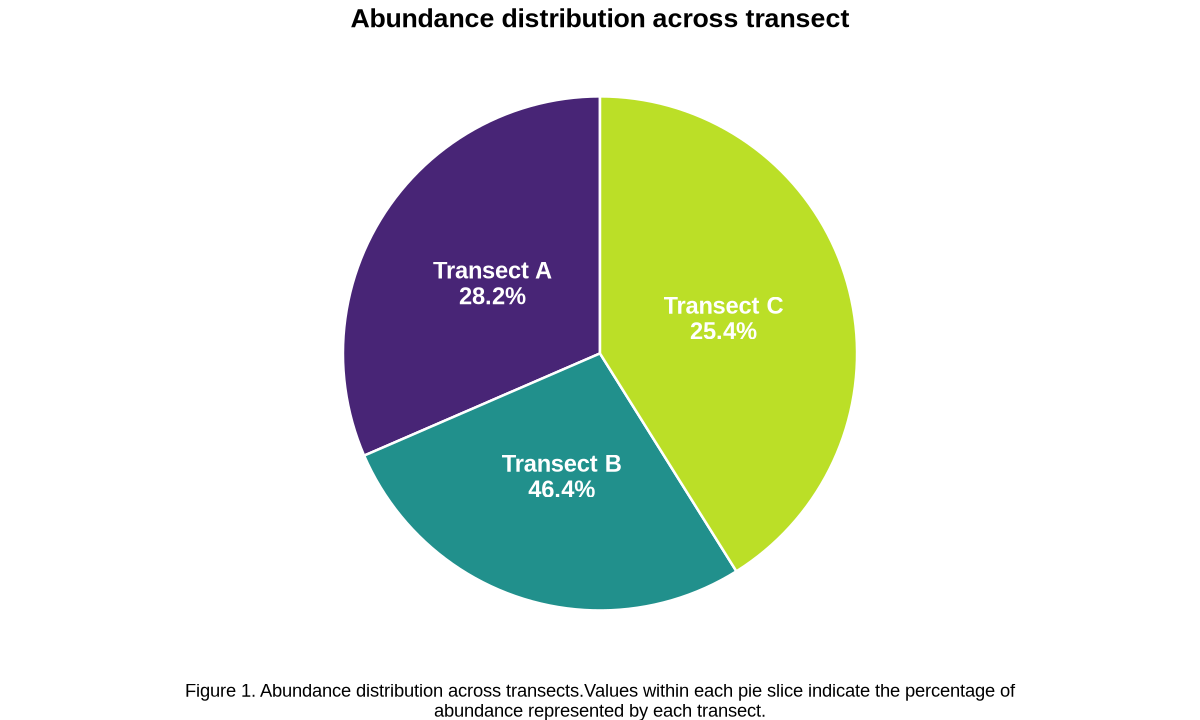

In [10]:
# Create a pie chart of the abundance distribution across transects
caption_text <- paste0(
    "Figure 1. Abundance distribution across transects.",
    "Values within each pie slice indicate the percentage of ",
    "abundance represented by each transect."
)

x.figure1 <- make_pie_chart(data_info, data_info$S.obs, data_info$Assemblage, data_info$label) +
    labs(
        title = "Abundance distribution across transect",
        caption = str_wrap(caption_text, width = 110)
    ) +
    theme(
        plot.title = element_text(hjust = 0.5, size = 16, face = "bold"),
        plot.caption = element_text(hjust = 0.5, size = 11),
        legend.position = "none"
    )

options(repr.plot.width = 10, repr.plot.height = 6)
x.figure1

#### Results
Table 1 summarizes the abundance and observed species richness of saproxylic fungal assemblages in Transects A, B, and C. Observed species richness varied among the three transects, with 23 species recorded in Transect A, 20 in Transect B, and 30 in Transect C. 

Figure 1 shows the distribution of saproxylic fungal abundance across Transects A, B, and C. Transect B accounted for the largest proportion of the total abundance at 46.4%, followed by Transect A at 28.2% and Transect C at 25.4%. 

The distribution shows that fungal occurrences were unevenly distributed among the three transects, with nearly half of the total abundance recorded in Transect B.

### 2.2. Observed and estimated diversity

In [11]:
# Asymptotic diversity estimates for Hill numbers (q = 0, 1, 2)
asy_est <- inext$AsyEst %>%
    mutate(
        `95% CI` = sprintf("%.2f – %.2f", LCL, UCL),
        Diversity_q = recode_values(
            Diversity,
            from = c("Species richness", "Shannon diversity", "Simpson diversity"),
            to = c("0", "1", "2"),
            default = Diversity
        )
    ) 

asy_est

Assemblage,Diversity,Observed,Estimator,s.e.,LCL,UCL,95% CI,Diversity_q
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
A,Species richness,23.000000,23.000000,0.70245916,23.000000,24.376795,23.00 – 24.38,0
A,Shannon diversity,5.932782,5.947331,0.10529992,5.740947,6.153715,5.74 – 6.15,1
A,Simpson diversity,3.996179,3.998802,0.08162800,3.838814,4.158790,3.84 – 4.16,2
B,Species richness,20.000000,20.000000,0.69340059,20.000000,21.359040,20.00 – 21.36,0
B,Shannon diversity,3.979509,3.984623,0.05619759,3.874478,4.094768,3.87 – 4.09,1
B,Simpson diversity,2.730684,2.731312,0.03364510,2.665368,2.797255,2.67 – 2.80,2
C,Species richness,30.000000,30.000000,0.78289482,30.000000,31.534446,30.00 – 31.53,0
C,Shannon diversity,8.511319,8.541814,0.18687249,8.175550,8.908077,8.18 – 8.91,1
C,Simpson diversity,5.613021,5.619310,0.10601620,5.411522,5.827097,5.41 – 5.83,2


#### Table 2: Observed and asymptotic Hill diversity estimates

In [12]:
# Create a publish-ready table of the asymptotic Hill diversity estimates
caption_text <- paste0(
    "Table 2: Observed and asymptotic Hill diversity estimates for saproxylic fungal ",
    "assemblages across Transects A, B, and C. Reported values include observed diversity, ",
    "estimated asymptotic diversity, and 95% confidence intervals for q = 0, 1, and 2."
)

x.table2 <- asy_est %>%
    select (
        Assemblage,
        Diversity_q,
        Observed,
        Estimator,
        `95% CI`,
    ) %>%
    gt() %>% 
    cols_label(
        Assemblage = md("**Transect**"),
        Diversity_q = md("**Diversity**"),
        Observed = md("**Observed**"),
        Estimator = md("**Asymptotic estimate**"),
        `95% CI` = md("**95% CI**"),
    ) %>%
    cols_align(
        align = "center",
        columns = 1
    ) %>%
    cols_align(
        align = "right",
        columns = 5
    ) %>%
    fmt(
        columns = Diversity_q,
        fns = function(x) {
            recode_values(x,
                "0" ~ "Species richness (q=0)", 
                "1" ~ "Shannon diversity (q=1)", 
                "2" ~ "Simpson diversity (q=2)"
            )
        }
    ) %>%
    fmt_number(
        columns = where(is.numeric),
        decimals = 2
    ) %>%
    tab_style(
        style = cell_text(align = "center"),
        locations = cells_column_labels(columns = everything())
    ) %>%
    tab_caption(
        caption = md(caption_text)
    ) 

In [13]:
x.table2 %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html()

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 2: Observed and asymptotic Hill diversity estimates for saproxylic fungal assemblages across Transects A, B, and C. Reported values include observed diversity, estimated asymptotic diversity, and 95% confidence intervals for q = 0, 1, and 2. <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_center" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Assemblage" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="Diversity_q" align="center" bgcolor="#FFFFFF" valign="bottom"> Diversity 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="Observed" align="center" bgcolor="#FFFFFF" valign="bottom"> Observed 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="Estimator" align="center" bgcolor="#FFFFFF" valign="bottom"> Asymptotic estimate 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left

#### Figure 2: Observed and estimated diversity across transects

In [14]:
asy_est

Assemblage,Diversity,Observed,Estimator,s.e.,LCL,UCL,95% CI,Diversity_q
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
A,Species richness,23.000000,23.000000,0.70245916,23.000000,24.376795,23.00 – 24.38,0
A,Shannon diversity,5.932782,5.947331,0.10529992,5.740947,6.153715,5.74 – 6.15,1
A,Simpson diversity,3.996179,3.998802,0.08162800,3.838814,4.158790,3.84 – 4.16,2
B,Species richness,20.000000,20.000000,0.69340059,20.000000,21.359040,20.00 – 21.36,0
B,Shannon diversity,3.979509,3.984623,0.05619759,3.874478,4.094768,3.87 – 4.09,1
B,Simpson diversity,2.730684,2.731312,0.03364510,2.665368,2.797255,2.67 – 2.80,2
C,Species richness,30.000000,30.000000,0.78289482,30.000000,31.534446,30.00 – 31.53,0
C,Shannon diversity,8.511319,8.541814,0.18687249,8.175550,8.908077,8.18 – 8.91,1
C,Simpson diversity,5.613021,5.619310,0.10601620,5.411522,5.827097,5.41 – 5.83,2


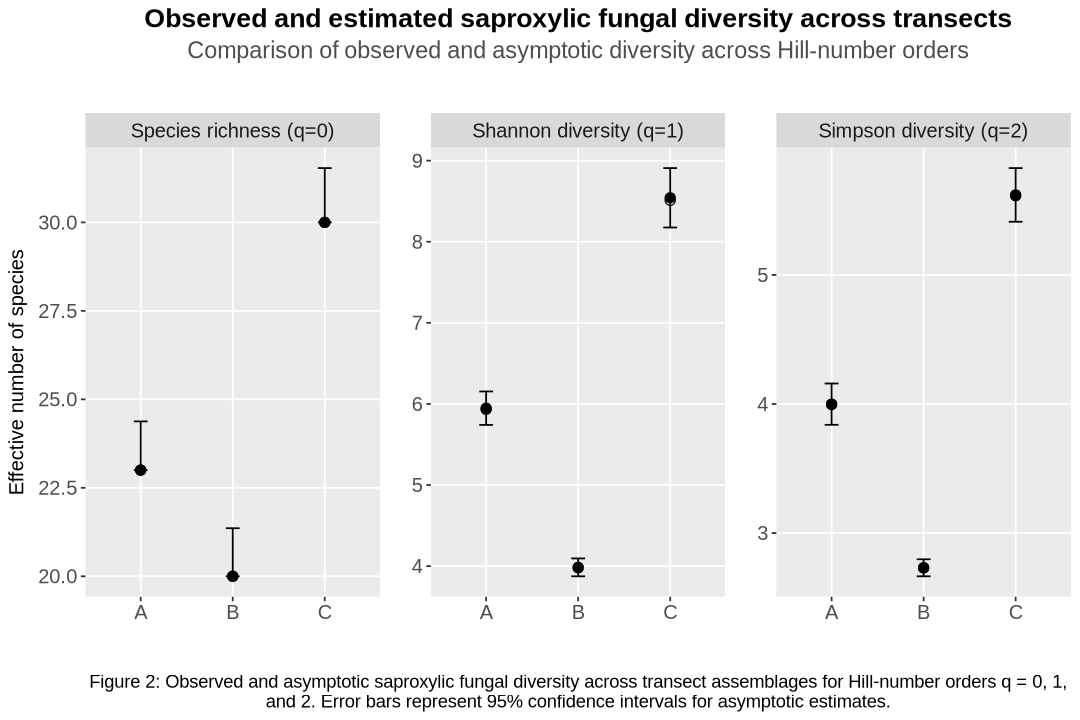

In [15]:
# Create a publish-ready plot of the asymptotic Hill diversity estimates
title_text <- "Observed and estimated saproxylic fungal diversity across transects"
subtitle_text <- "Comparison of observed and asymptotic diversity across Hill-number orders"
caption_text <- paste0(
    "Figure 2: Observed and asymptotic saproxylic fungal diversity across transect assemblages ",
    "for Hill-number orders q = 0, 1, and 2. Error bars represent 95% confidence intervals for ",
    "asymptotic estimates."
)

x.figure2 <- ggplot(asy_est, aes(x = Assemblage, y = Estimator)) +
    geom_point(size = 2.5) +
    geom_errorbar(
        aes(ymin = LCL, ymax = UCL),
        width = 0.15
    ) +
    geom_point(aes(y = Observed), shape = 1, size = 2.5) +
    facet_wrap(
        ~ Diversity_q,
        labeller = as_labeller(
            c(
                "0" = "Species richness (q=0)", 
                "1" = "Shannon diversity (q=1)", 
                "2" = "Simpson diversity (q=2)"
            )
        ),
        scales = "free_y"
    ) +
    labs(
        x = NULL,
        y = "Effective number of species"
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

options(repr.plot.width = 9, repr.plot.height = 6)
x.figure2

#### Results
Table 2 summarizes the observed and estimated asymptotic diversity of the saproxylic fungal assemblages across transects while Figure 2 provides a visual comparison of these estimates. Diversity was evaluated using Hill-number orders *q* = 0, *q* = 1, and *q* = 2, representing species richness, Shannon diversity, and Simpson diversity, respectively.

For species richness (_q = 0_), observed diversity varied among the three transects, with _23_ species recorded in Transect A, _20_ in Transect B, and _30_ in Transect C. The corresponding asymptotic estimates were identical to the observed values for all three transect assemblages. This result is likely influenced by preprocessing of the dataset, particularly the removal of singleton and doubleton taxa, which reduces the rare-species information used to estimate undetected diversity.

At _q = 1_, exponential Shannon diversity was _5.95_ for Transect A, _3.80_ for Transect B, and _8.54_ for Transect C. Observed and asymptotic estimates were very similar across the three transects, although this convergence should be interpreted in the context of the prior filtering of rare taxa.

At _q = 2_, inverse Simpson diversity was _4.00_ for Transect A, _2.73_ for Transect B, and _5.62_ for Transect C. Observed and asymptotic estimates were nearly identical, indicating that little additional diversity attributable to common and dominant species was estimated beyond that represented in the observed assemblages.

Overall, diversity followed the consistent pattern **Transect C > Transect A > Transect B** across all three Hill-number orders (_q = 0, 1, and 2_). Transect C was not only the richest in terms of total species but also exhibited the greatest effective diversity when progressively greater weight was given to common and dominant taxa. Conversely, Transect B consistently exhibited the lowest diversity across all three diversity orders.

### 2.3. Sample size diversity (type = 1)

#### Figure 3: Sample size diversity across Hill-number orders

In [16]:
# Convert iNEXT output to plotting data for type = 1
plot_data <- fortify(inext, type = 1)

# Format variables
plot_data <- plot_data %>%
    mutate(
        Transect = factor(Assemblage, levels = c("A", "B", "C")),
        Order.q = factor(
            Order.q,
            levels = c(0, 1, 2),
            labels = c(
                "Species richness (q = 0)",
                "Shannon diversity (q = 1)",
                "Simpson diversity (q = 2)"
            )
        )
    )

# Preserve the observed/reference points BEFORE filtering
observed_data <- plot_data %>%
    filter(Method == "Observed")

# Retain only rarefaction and extrapolation curves
plot_data <- plot_data %>%
    filter(Method %in% c("Rarefaction", "Extrapolation"))

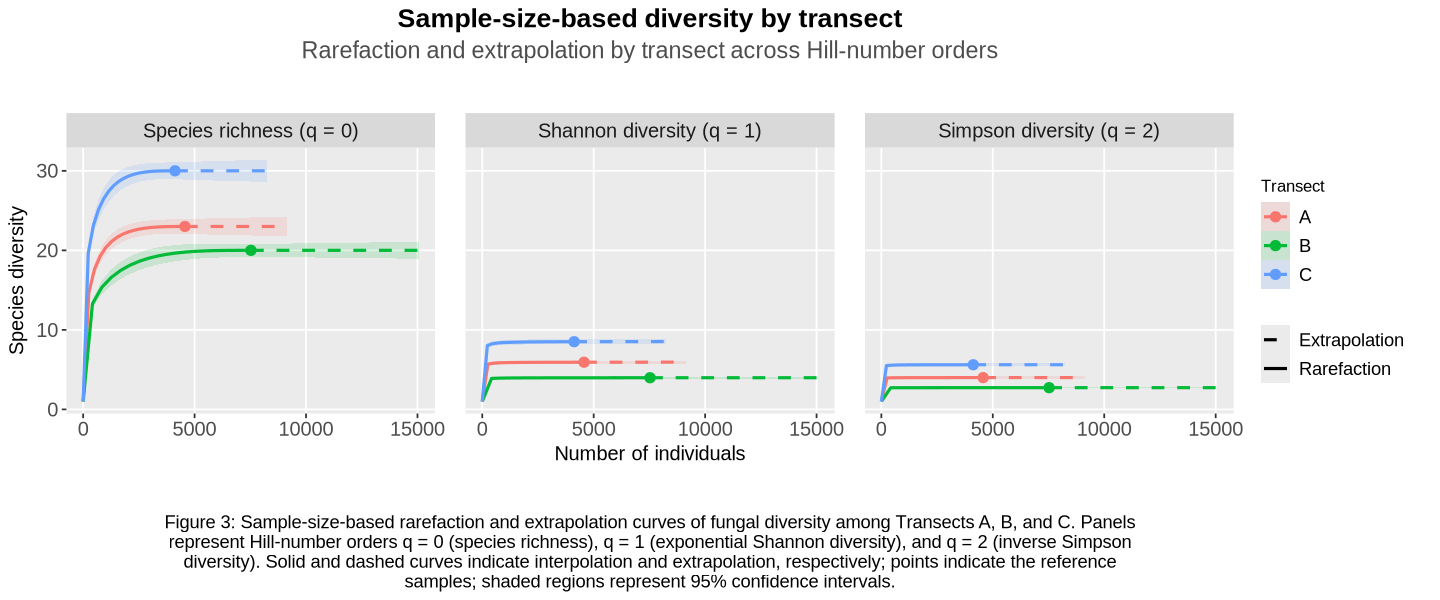

In [17]:
title_text <- paste0(
    "Sample-size-based diversity by transect"
)

subtitle_text <- paste0(
    "Rarefaction and extrapolation by transect across Hill-number orders"
)

caption_text <- paste0(
    "Figure 3: Sample-size-based rarefaction and extrapolation curves of fungal diversity among Transects A, B, and C. ",
    "Panels represent Hill-number orders q = 0 (species richness), q = 1 (exponential Shannon diversity), ",
    "and q = 2 (inverse Simpson diversity). Solid and dashed curves indicate interpolation and extrapolation, ",
    "respectively; points indicate the reference samples; shaded regions represent 95% confidence intervals."
)

x.figure3 <- ggplot(plot_data,
        aes(
            x = x,
            y = y,
            color = Transect,
            fill = Transect
        )
    ) +
    geom_ribbon(
        aes(
            ymin = y.lwr,
            ymax = y.upr,
            group = interaction(Transect, Method)
        ),
        alpha = 0.15,
        linewidth = 0
    ) +
    geom_line(
        aes(linetype = Method, group = interaction(Transect, Method)),
        linewidth = 0.9
    ) +
    geom_point(
        data = observed_data,
        aes(x = x, y = y, color = Transect),
        inherit.aes = FALSE,
        size = 2.5
    ) +
    scale_linetype_manual(
        values = c(
            "Rarefaction" = "solid",
            "Extrapolation" = "dashed"
        )
    ) +
    facet_wrap(
        ~ Order.q,
        nrow = 1,
        scales = "fixed"
    ) +
    labs(
        x = "Number of individuals",
        y = "Species diversity",
        color = "Transect",
        fill = "Transect",
        linetype = NULL
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

options(repr.plot.width = 12, repr.plot.height = 5)
x.figure3

#### Results
Figure 3 presents sample-size-based rarefaction and extrapolation curves comparing saproxylic fungal diversity among Transects A, B, and C separately for each Hill-number order. Diversity increased with sample size during the initial portion of sampling, after which the curves gradually flattened and approached a plateau with extended extrapolation. This pattern was evident across the three transects and diversity orders, indicating that relatively little additional diversity was predicted with further increases in sample size.

### 2.4. Sampling completeness (type = 2)

#### Figure 4: Sampling completeness by transect

In [18]:
# Extract sample-completeness data
plot_data <- fortify(inext, type = 2)

# Format variables for transect-only analysis
plot_data <- plot_data %>%
    mutate(
        Transect = factor(Assemblage, levels = c("A", "B", "C"))
    )

# Preserve observed/reference points BEFORE changing Method
observed_data <- plot_data %>%
    filter(Method == "Observed")

# Treat the observed point as the endpoint of the rarefaction curve
plot_data <- plot_data %>%
    mutate(
        Method = if_else(Method == "Observed", "Rarefaction", Method),
        Method = factor(Method, levels = c("Rarefaction", "Extrapolation"))
    )

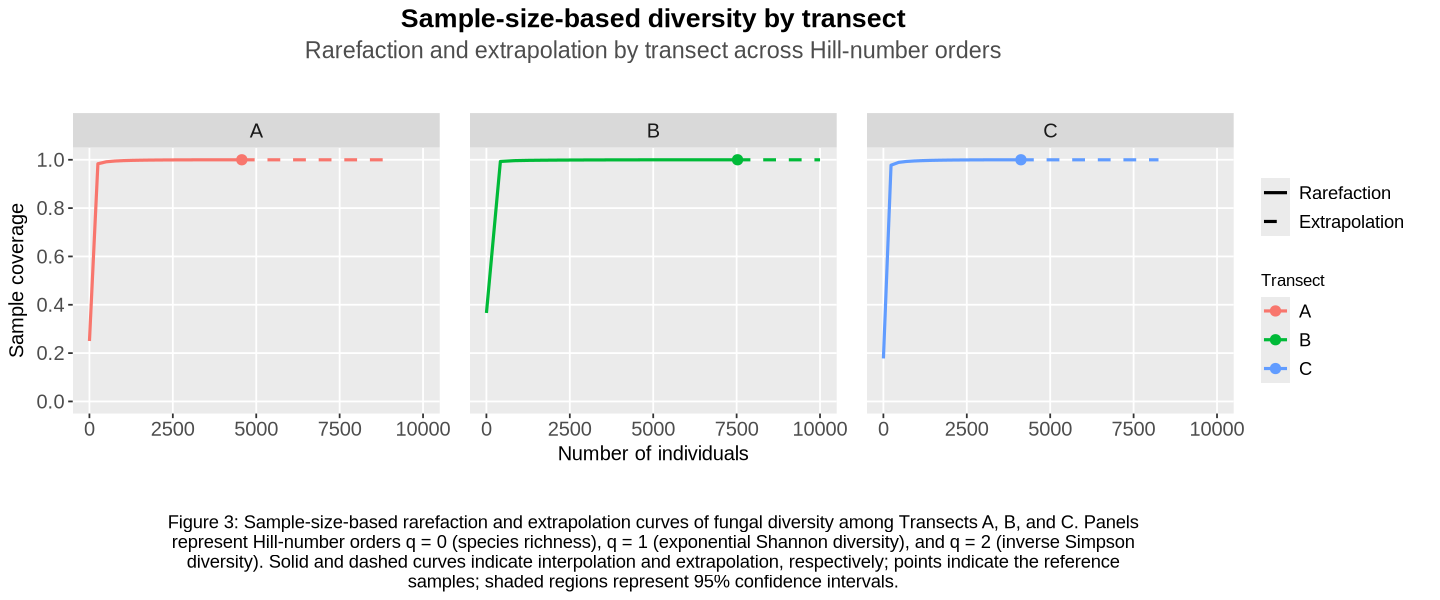

In [19]:
x.figure4 <- ggplot(plot_data,
        aes(
            x = x,
            y = y,
            color = Transect,
            linetype = Method,
            group = interaction(Transect, Method)
        )
    ) +
    geom_line(linewidth = 0.9) +
    # Observed/reference sample
    geom_point(
        data = observed_data,
        aes(x = x, y = y, color = Transect),
        inherit.aes = FALSE,
        size = 2.5
    ) +
    facet_wrap(
        ~ Transect,
        nrow = 1
    ) +
    scale_linetype_manual(
        values = c(
            "Rarefaction" = "solid",
            "Extrapolation" = "dashed"
        )
    ) +
    scale_x_continuous(limits = c(0, 10000), oob = squish) +
    scale_y_continuous(limits = c(0, 1), breaks = seq(0, 1, 0.2)) +
    labs(
        x = "Number of individuals",
        y = "Sample coverage",
        color = "Transect",
        linetype = NULL
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

options(repr.plot.width = 12, repr.plot.height = 5)
x.figure4

#### Results
Figure 4 presents sample completeness curves for the saproxylic fungal assemblages of Transects A, B, and C. Sample coverage increased steeply with the number of individuals and approached _1.00_ at relatively small sample sizes across all three transects. Beyond the observed reference samples, extrapolated coverage remained close to _1.00_, indicating that additional increases in sample size were predicted to yield little improvement in estimated sample completeness.

### 2.5. Sample Coverage (type = 3)

#### Figure 5: Coverage-based diversity across Hill-number orders

In [20]:
# Use the actual coverage-based iNEXT estimates
plot_data <- inext$iNextEst$coverage_based

# Preserve observed/reference points BEFORE modifying Method
observed_data <- plot_data %>%
    filter(Method == "Observed") %>%
    mutate(
        Transect = factor(Assemblage, levels = c("A", "B", "C")),
        Order.q = factor(
            Order.q,
            levels = c(0, 1, 2),
            labels = c(
                "Species richness (q = 0)",
                "Shannon diversity (q = 1)",
                "Simpson diversity (q = 2)"
            )
        )
    )

# Prepare transect-only plotting data
plot_data <- plot_data %>%
    mutate(
        Transect = factor(Assemblage, levels = c("A", "B", "C")),
        Order.q = factor(
            Order.q,
            levels = c(0, 1, 2),
            labels = c(
                "Species richness (q = 0)",
                "Shannon diversity (q = 1)",
                "Simpson diversity (q = 2)"
            )
        ),
        # Treat observed estimate as the endpoint
        # of the rarefaction curve
        Method = if_else(Method == "Observed", "Rarefaction", Method),
        Method = factor(Method, levels = c("Rarefaction", "Extrapolation"))
    )

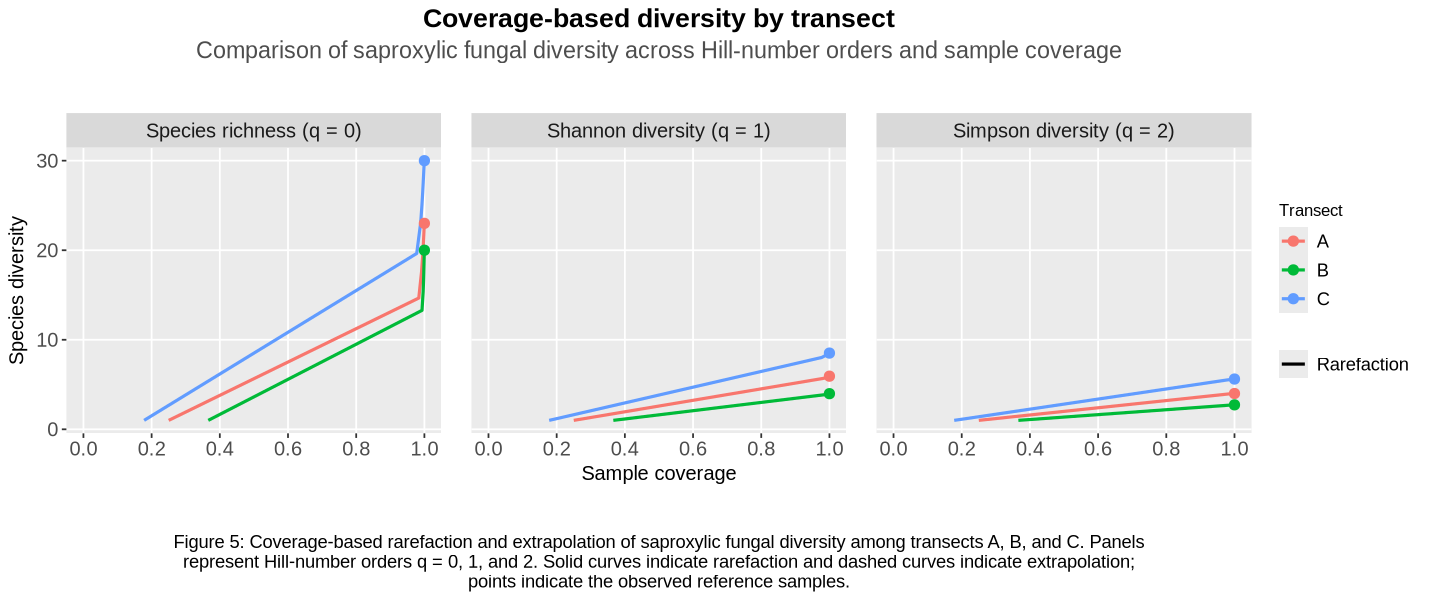

In [21]:
title_text <- paste0(
    "Coverage-based diversity by transect"
)

subtitle_text <- paste0(
    "Comparison of saproxylic fungal diversity across Hill-number orders and sample coverage"
)

caption_text <- paste0(
    "Figure 5: Coverage-based rarefaction and extrapolation of saproxylic fungal diversity ",
    "among transects A, B, and C. Panels represent Hill-number orders q = 0, 1, and 2. ",
    "Solid curves indicate rarefaction and dashed curves indicate extrapolation; ",
    "points indicate the observed reference samples."
)

x.figure5 <- ggplot(plot_data,
        aes(
            x = SC,
            y = qD,
            color = Transect,
            linetype = Method,
            group = interaction(Transect, Method)
        )
    ) +
    geom_line(linewidth = 0.9) +
    # Observed/reference points
    geom_point(
        data = observed_data,
        aes(
            x = SC,
            y = qD,
            color = Transect
        ),
        inherit.aes = FALSE,
        size = 2.5
    ) +
    # Shared y-axis across Hill-number panels
    facet_wrap(
        ~ Order.q,
        nrow = 1,
        scales = "fixed"
    ) +
    scale_linetype_manual(
        values = c(
            "Rarefaction" = "solid",
            "Extrapolation" = "dashed"
        )
    ) +
    scale_x_continuous(limits = c(0, 1), breaks = seq(0, 1, 0.2)) +
    labs(
        x = "Sample coverage",
        y = "Species diversity",
        color = "Transect",
        linetype = NULL
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

options(repr.plot.width = 12, repr.plot.height = 5)
x.figure5

#### Results
Figure 5 presents the coverage-based diversity curves organized by Hill-number order, allowing direct comparison of Transects A, B, and C at equivalent levels of sample coverage.

Across all three Hill-number orders, Transect C consistently exhibited the highest diversity, followed by Transect A and Transect B. This ranking was maintained for species richness (_q = 0_), exponential Shannon diversity (_q = 1_), and inverse Simpson diversity (_q = 2_). The persistence of the same ordering as progressively greater weight was placed on common and dominant taxa indicates that the higher diversity of Transect C was not restricted to rare species, but was also evident in the abundance structure of the assemblage.

Importantly, because Figure 5 expresses diversity relative to sample coverage, the persistence of the pattern **Transect C > Transect A > Transect B** indicates that the observed ranking is maintained when the transects are compared at equivalent levels of sampling completeness. Thus, the differences among transects are unlikely to be attributable solely to unequal sampling completeness.

## 3. Diversity by Transect and Wood Texture

In [22]:
# Create the abundance list based on transects and wood textures
saproxylic_df <- cbind(environment_df$Transect, environment_df$Wood.Texture, saproxylic_community_df)
names(saproxylic_df)[1:2] =  c("Transect", "Wood.Texture")         # Environment columns as Site
saproxylic_df <- saproxylic_df %>%
    group_by(Transect, Wood.Texture) %>%
    summarise(
        across(3:last_col(), sum),                                 # OTU counts
        .groups = "drop"
      ) %>%
    mutate(Site = paste(Transect,"-",Wood.Texture, sep="")) %>%    # New site column
    relocate(Site) %>%
    select(-Transect, -Wood.Texture)                               # Remove environment columns

site_names = saproxylic_df$Site

saproxylic_df <- saproxylic_df %>%
    select(-Site)
saproxylic_df <- as.data.frame(t(saproxylic_df))
names(saproxylic_df) <- site_names

head(saproxylic_df)

,A-Hardwood,A-Softwood,B-Hardwood,B-Softwood,C-Hardwood,C-Softwood
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Ascocoryne,0,0,1,69,1,36
Atheliachaete,0,0,0,3,0,0
Botryobasidium,0,0,0,6,0,0
Ceraceomyces,42,39,1,3,928,20
Cistella,4,10,0,0,0,40
Claussenomyces,0,0,0,0,0,5


In [23]:
# Prepare the abundance list for iNEXT
abundance_list <- lapply(saproxylic_df, function(x) x[x != 0])
abundance_list

$`A-Hardwood`
 [1]  42   4  13   3 167   2   2   5  31  24  77  40  51 296   6  10  19 676

$`A-Softwood`
 [1]   39   10   20    1    3  433   10    1  540    1    1    5  109    7   41
[16]   36  558    3    2    1    4 1268

$`B-Hardwood`
 [1]    1    1    5   71   86  118    1    6  102  771   11   16    2 2029

$`B-Softwood`
 [1]   69    3    6    3    5   49    5   51  135   25   32   18    7   55 1480
[16]   45  426    3    1 1890

$`C-Hardwood`
 [1]   1 928  91   2 196  49 279   2   2   3   1  54  28   2   2  27   2   1   3
[20]   4   8   1

$`C-Softwood`
 [1]   36   20   40    5    2   46   11    8  654    1    5   50   21    9   27
[16]    5   17   19    3  126 1059    4    9    3   59    3

In [24]:
# computes rarefaction (interpolation) and extrapolation (prediction) sampling curves for biodiversity 
# standard comparisons across communities using Hill numbers 
#   q=0 for species richness, 
#   q=1 for Shannon diversity, and 
#   q=2 for Simpson diversity
inext <- iNEXT(abundance_list, q=c(0, 1, 2), datatype="abundance")

### 3.1. Abundance, species richness, and sample coverage

In [25]:
data_info <- inext$DataInfo %>%
    separate_wider_delim(
        cols = Assemblage, 
        delim = "-", 
        names = c("Transect", "Wood.Texture"),
        cols_remove = FALSE
    ) %>%
    mutate(
        Description = recode_values(
            Transect,
            from = c("A", "B", "C"),
            to = c("conifer forest with access of reindeer", 
                   "conifer forest without access of reindeer", 
                   "broadleaf forest and accessed to tourists"),
            default = Transect
        ),
        Sample_Coverage = paste0(SC * 100, "%")
    ) %>%
    select(
        Assemblage,
        Transect,
        Description,
        Wood.Texture,
        n,
        S.obs,
        Sample_Coverage
    )

data_info

Assemblage,Transect,Description,Wood.Texture,n,S.obs,Sample_Coverage
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
A-Hardwood,A,conifer forest with access of reindeer,Hardwood,1468,18,100%
A-Softwood,A,conifer forest with access of reindeer,Softwood,3093,22,99.84%
B-Hardwood,B,conifer forest without access of reindeer,Hardwood,3220,14,99.91%
B-Softwood,B,conifer forest without access of reindeer,Softwood,4308,20,100%
C-Hardwood,C,broadleaf forest and accessed to tourists,Hardwood,1686,22,99.76%
C-Softwood,C,broadleaf forest and accessed to tourists,Softwood,2242,26,99.96%


#### Table 3: Abundance and observed species richness

In [26]:
# Create a publish-ready table of the summary data
caption_text <- paste0(
    "Table 3: Abundance, observed species richness, and sample coverage ",
    "by transect and wood texture."
)

y.table1 <- data_info %>%
    select (
        Transect,
        Description,
        Wood.Texture,
        n,
        S.obs,
        Sample_Coverage
    ) %>%
    gt() %>% 
    cols_label(
        Transect = md("**Transect**"),
        Description = md("**Description**"),
        Wood.Texture = md("**Wood Texture**"),
        n = md("**Abundance**"),
        S.obs = md("**Observed Richness**"),
        Sample_Coverage = md("**Sample Coverage**")
    ) %>%
    cols_align(
        align = "center",
        columns = 1
    ) %>%
    tab_style(
        style = cell_text(align = "center"),
        locations = cells_column_labels(columns = everything())
    ) %>%
    tab_caption(
        caption = md(caption_text)
    ) 

In [27]:
y.table1 %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html()

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 3: Abundance, observed species richness, and sample coverage by transect and wood texture. <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_center" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Transect" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Description" align="center" bgcolor="#FFFFFF" valign="bottom"> Description 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Wood.Texture" align="center" bgcolor="#FFFFFF" valign="bottom"> Wood Texture 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="n" align="center" bgcolor="#FFFFFF" valign="bottom"> Abundance 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-num

Table 3 summarizes the abundance and observed species richness of saproxylic fungal assemblages in different wood textures (hardwood and softwood) found in Transects A, B, and C. Observed species richness varied among wood types within transects with 18 species found in hardwood and 22 species in softwoood for Transect A, 14 species found in hardwood and 20 species in softwoood for Transect B, and 22 species found in hardwood and 26 species in softwoood for Transect C. 

#### Figure 6: Abundance distribution across transects and wood textures

In [28]:
a_data_info <- data_info %>%
    filter(Transect == "A") %>%
    mutate(
        percentage = n / sum(n) * 100,
        label = paste0(Wood.Texture, "\n(", round(percentage, 1), "%)")
    )

a_data_info

Assemblage,Transect,Description,Wood.Texture,n,S.obs,Sample_Coverage,percentage,label
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<chr>
A-Hardwood,A,conifer forest with access of reindeer,Hardwood,1468,18,100%,32.18592,Hardwood (32.2%)
A-Softwood,A,conifer forest with access of reindeer,Softwood,3093,22,99.84%,67.81408,Softwood (67.8%)


In [29]:
b_data_info <- data_info %>%
    filter(Transect == "B") %>%
    mutate(
        percentage = n / sum(n) * 100,
        label = paste0(Wood.Texture, "\n(", round(percentage, 1), "%)")
    )

b_data_info

Assemblage,Transect,Description,Wood.Texture,n,S.obs,Sample_Coverage,percentage,label
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<chr>
B-Hardwood,B,conifer forest without access of reindeer,Hardwood,3220,14,99.91%,42.77365,Hardwood (42.8%)
B-Softwood,B,conifer forest without access of reindeer,Softwood,4308,20,100%,57.22635,Softwood (57.2%)


In [30]:
c_data_info <- data_info %>%
    filter(Transect == "C") %>%
    mutate(
        percentage = n / sum(n) * 100,
        label = paste0(Wood.Texture, "\n(", round(percentage, 1), "%)")
    )

c_data_info

Assemblage,Transect,Description,Wood.Texture,n,S.obs,Sample_Coverage,percentage,label
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<chr>
C-Hardwood,C,broadleaf forest and accessed to tourists,Hardwood,1686,22,99.76%,42.92261,Hardwood (42.9%)
C-Softwood,C,broadleaf forest and accessed to tourists,Softwood,2242,26,99.96%,57.07739,Softwood (57.1%)


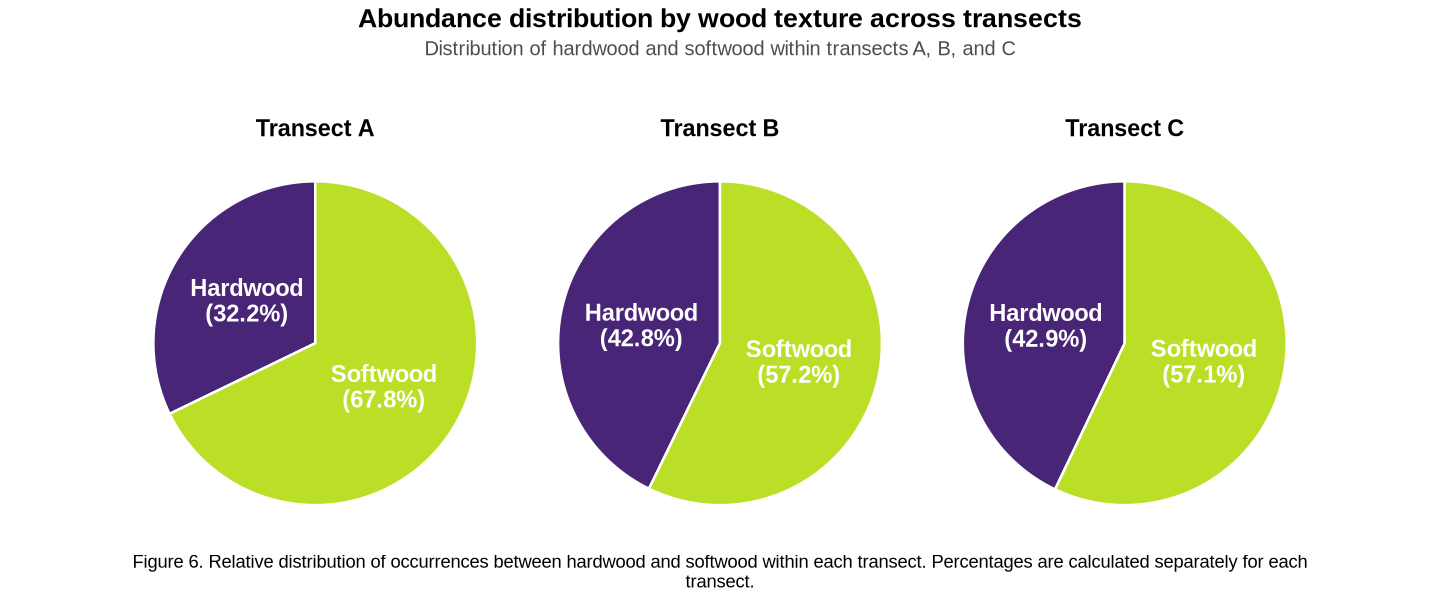

In [31]:
a_pie_chart <- make_pie_chart(a_data_info, a_data_info$percentage, a_data_info$Wood.Texture, a_data_info$label) +
    labs(title = "Transect A") +
    theme(
        plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
        legend.position = "none"
    )

b_pie_chart <- make_pie_chart(b_data_info, b_data_info$percentage, b_data_info$Wood.Texture, b_data_info$label) +
    labs(title = "Transect B") +
    theme(
        plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
        legend.position = "none"
    )

c_pie_chart <- make_pie_chart(c_data_info, c_data_info$percentage, c_data_info$Wood.Texture, c_data_info$label) +
    labs(title = "Transect C") +
    theme(
        plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
        legend.position = "none"
    )

caption_text <- paste0(
    "Figure 6. Relative distribution of occurrences between hardwood and softwood ",
    "within each transect. Percentages are calculated separately for each transect."
)

title_and_caption <- plot_annotation(
    title = "Abundance distribution by wood texture across transects",
    subtitle = "Distribution of hardwood and softwood within transects A, B, and C",
    caption = str_wrap(caption_text, width = 150),
    theme = theme(
        plot.title = element_text(size = 16, face = "bold", hjust = 0.5),
        plot.subtitle = element_text(hjust = 0.5, size = 12, color = "grey30", margin = margin(b=30)),
        plot.caption = element_text(hjust = 0.5, size = 11)
    )
)

combined_pie_chart <-
    a_pie_chart + b_pie_chart + c_pie_chart + title_and_caption    

y.figure1 <- combined_pie_chart
y.figure1

#### Results
Table 3 summarizes the abundance and species richness of saproxylic fungal assemblages across hardwood and softwood textures in Transects A, B, and C. Species richness was consistently higher in softwood than in hardwood across all transects; softwood values ranged from 20 to 26 species, whereas hardwood values ranged from 14 to 22 species. 

Similarly, Figure 6 illustrates the distribution of fungal abundance, revealing a consistent trend where softwood textures supported a higher proportion of the community (57.1%–67.8%) compared to hardwood textures (32.2%–42.9%).

### 3.2. Observed and estimated diversity

In [32]:
asy_est <- inext$AsyEst %>%
    separate_wider_delim(
        cols = Assemblage, 
        delim = "-", 
        names = c("Transect", "Wood.Texture"),
        cols_remove = FALSE
    ) %>%
    mutate(
        `95% CI` = sprintf("%.2f – %.2f", LCL, UCL),
        Diversity_q = recode_values(
            Diversity,
            from = c("Species richness", "Shannon diversity", "Simpson diversity"),
            to = c("0", "1", "2"),
            default = Diversity
        )
    ) 

asy_est

Transect,Wood.Texture,Assemblage,Diversity,Observed,Estimator,s.e.,LCL,UCL,95% CI,Diversity_q
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
A,Hardwood,A-Hardwood,Species richness,18.000000,18.000000,0.87275291,18.000000,19.710564,18.00 – 19.71,0
A,Hardwood,A-Hardwood,Shannon diversity,5.858099,5.892891,0.19278873,5.515032,6.270750,5.52 – 6.27,1
A,Hardwood,A-Hardwood,Simpson diversity,3.673528,3.680235,0.13718664,3.411355,3.949116,3.41 – 3.95,2
A,Softwood,A-Softwood,Species richness,22.000000,34.495959,10.12306796,22.000000,54.336807,22.00 – 54.34,0
A,Softwood,A-Softwood,Shannon diversity,5.313846,5.341920,0.10847839,5.129307,5.554534,5.13 – 5.55,1
A,Softwood,A-Softwood,Simpson diversity,3.960734,3.964530,0.07964446,3.808430,4.120630,3.81 – 4.12,2
B,Hardwood,B-Hardwood,Species richness,14.000000,18.498602,3.87204068,14.000000,26.087663,14.00 – 26.09,0
B,Hardwood,B-Hardwood,Shannon diversity,3.078053,3.086810,0.05937593,2.970435,3.203184,2.97 – 3.20,1
B,Hardwood,B-Hardwood,Simpson diversity,2.183514,2.184317,0.03995752,2.106002,2.262633,2.11 – 2.26,2


#### Table 4: Observed and asymptotic Hill diversity estimates

In [33]:
# Create a publish-ready table of the asymptotic Hill diversity estimates
caption_text <- paste0(
    "Table 4: Observed and asymptotic Hill diversity estimates for saproxylic fungal ",
    "assemblages across Transects A, B, and C and wood textures. Reported values ",
    "include observed diversity, estimated asymptotic diversity, and 95% confidence ",
    "intervals for q = 0, 1, and 2."
)

y.table2 <- asy_est %>%
    select (
        Transect,
        Wood.Texture,
        Diversity_q,
        Observed,
        Estimator,
        `95% CI`,
    ) %>%
    gt() %>% 
    cols_label(
        Transect = md("**Transect**"),
        Wood.Texture = md("**Wood Texture**"),
        Diversity_q = md("**Diversity**"),
        Observed = md("**Observed**"),
        Estimator = md("**Asymptotic estimate**"),
        `95% CI` = md("**95% CI**"),
    ) %>%
    cols_align(
        align = "center",
        columns = 1
    ) %>%
    cols_align(
        align = "right",
        columns = 5
    ) %>%
    fmt(
        columns = Diversity_q,
        fns = function(x) {
            recode_values(x,
                "0" ~ "Species richness (q=0)", 
                "1" ~ "Shannon diversity (q=1)", 
                "2" ~ "Simpson diversity (q=2)"
            )
        }
    ) %>%
    fmt_number(
        columns = where(is.numeric),
        decimals = 2
    ) %>%
    tab_style(
        style = cell_text(align = "center"),
        locations = cells_column_labels(columns = everything())
    ) %>%
    tab_caption(
        caption = md(caption_text)
    ) 

In [34]:
y.table2 %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html()

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 4: Observed and asymptotic Hill diversity estimates for saproxylic fungal assemblages across Transects A, B, and C and wood textures. Reported values include observed diversity, estimated asymptotic diversity, and 95% confidence intervals for q = 0, 1, and 2. <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_center" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Transect" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Wood.Texture" align="center" bgcolor="#FFFFFF" valign="bottom"> Wood Texture 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="Diversity_q" align="center" bgcolor="#FFFFFF" valign="bottom"> Diversity 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="Observed" align="center" bgcolor="#FFFFFF" valign="bottom"> Observed 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-r

#### Figure 7: Observed and estimated diversity across transects

#### Results

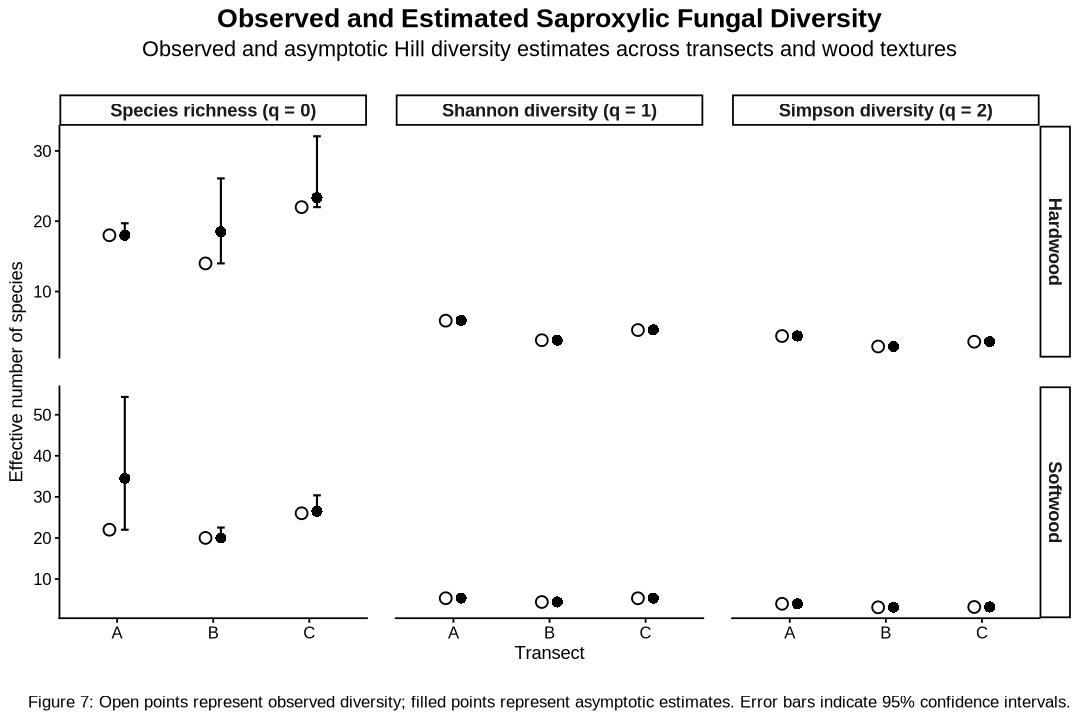

In [35]:
asy_est <- asy_est %>%
    mutate(
        Transect = factor(
            Transect,
            levels = c("A", "B", "C")
        ),
        Wood.Texture = factor(
            Wood.Texture,
            levels = c("Hardwood", "Softwood")
        ),
        Diversity_q = factor(
            Diversity_q,
            levels = c("0", "1", "2")
        )
    )

y.figure2 <- ggplot(
    asy_est,
    aes(
        x = Transect,
        y = Estimator
    )
) +
    # 95% CI for asymptotic estimate
    geom_errorbar(
        aes(
            ymin = LCL,
            ymax = UCL
        ),
        width = 0.08,
        linewidth = 0.6,
        position = position_nudge(x = 0.08)
    ) +

    # Asymptotic estimate
    geom_point(
        shape = 16,
        size = 2.8,
        position = position_nudge(x = 0.08)
    ) +

    # Observed diversity
    geom_point(
        aes(y = Observed),
        shape = 1,
        stroke = 0.8,
        size = 2.8,
        position = position_nudge(x = -0.08)
    ) +

    facet_grid(
        rows = vars(Wood.Texture),
        cols = vars(Diversity_q),
        labeller = labeller(
            Diversity_q = c(
                "0" = "Species richness (q = 0)",
                "1" = "Shannon diversity (q = 1)",
                "2" = "Simpson diversity (q = 2)"
            )
        ),
        scales = "free_y"
    ) +

    labs(
        x = "Transect",
        y = "Effective number of species",
        title = "Observed and Estimated Saproxylic Fungal Diversity",
        subtitle = paste(
            "Observed and asymptotic Hill diversity estimates",
            "across transects and wood textures"
        ),
        caption = paste(
            "Figure 7: Open points represent observed diversity; filled points represent",
            "asymptotic estimates. Error bars indicate 95% confidence intervals."
        )
    ) +

    theme_classic() +
    theme(
        plot.title = element_text(
            hjust = 0.5,
            size = 16,
            face = "bold"
        ),
        plot.subtitle = element_text(
            hjust = 0.5,
            size = 13,
            margin = margin(b = 20)
        ),
        strip.text = element_text(
            size = 11,
            face = "bold"
        ),
        axis.title = element_text(size = 11),
        axis.text = element_text(size = 10),
        panel.spacing = unit(1.2, "lines"),
        plot.caption = element_text(
            hjust = 0.5,
            size = 10,
            margin = margin(t = 20)
        )
    )

options(repr.plot.width = 9, repr.plot.height = 6)
y.figure2

### 3.3. Sample size diversity (type = 1)

In [36]:
# Convert iNEXT output to plotting data for type = 1
plot_data <- fortify(inext, type = 1)

# Split Assemblage into Transect and Wood Texture
plot_data <- plot_data %>%
    separate(
        Assemblage,
        into = c("Transect", "Wood.Texture"),
        sep = "-",
        remove = FALSE
    ) %>%
    mutate(
        Transect = factor(
            Transect,
            levels = c("A", "B", "C")
        ),
        Wood.Texture = factor(
            Wood.Texture,
            levels = c("Hardwood", "Softwood")
        ),
        Order.q = factor(
            Order.q,
            levels = c(0, 1, 2),
            labels = c(
                "Species richness (q = 0)",
                "Shannon diversity (q = 1)",
                "Simpson diversity (q = 2)"
            )
        )
    )

# Preserve the observed/reference points
observed_data <- plot_data %>%
    filter(Method == "Observed")

# Treat observed as the endpoint of the rarefaction curve
plot_data <- plot_data %>%
    mutate(
        Method = if_else(Method == "Observed", "Rarefaction", Method),
        Method = factor(
            Method,
            levels = c("Rarefaction", "Extrapolation")
        )
    )

#### Figure 8: Sample size diversity across Hill-number orders

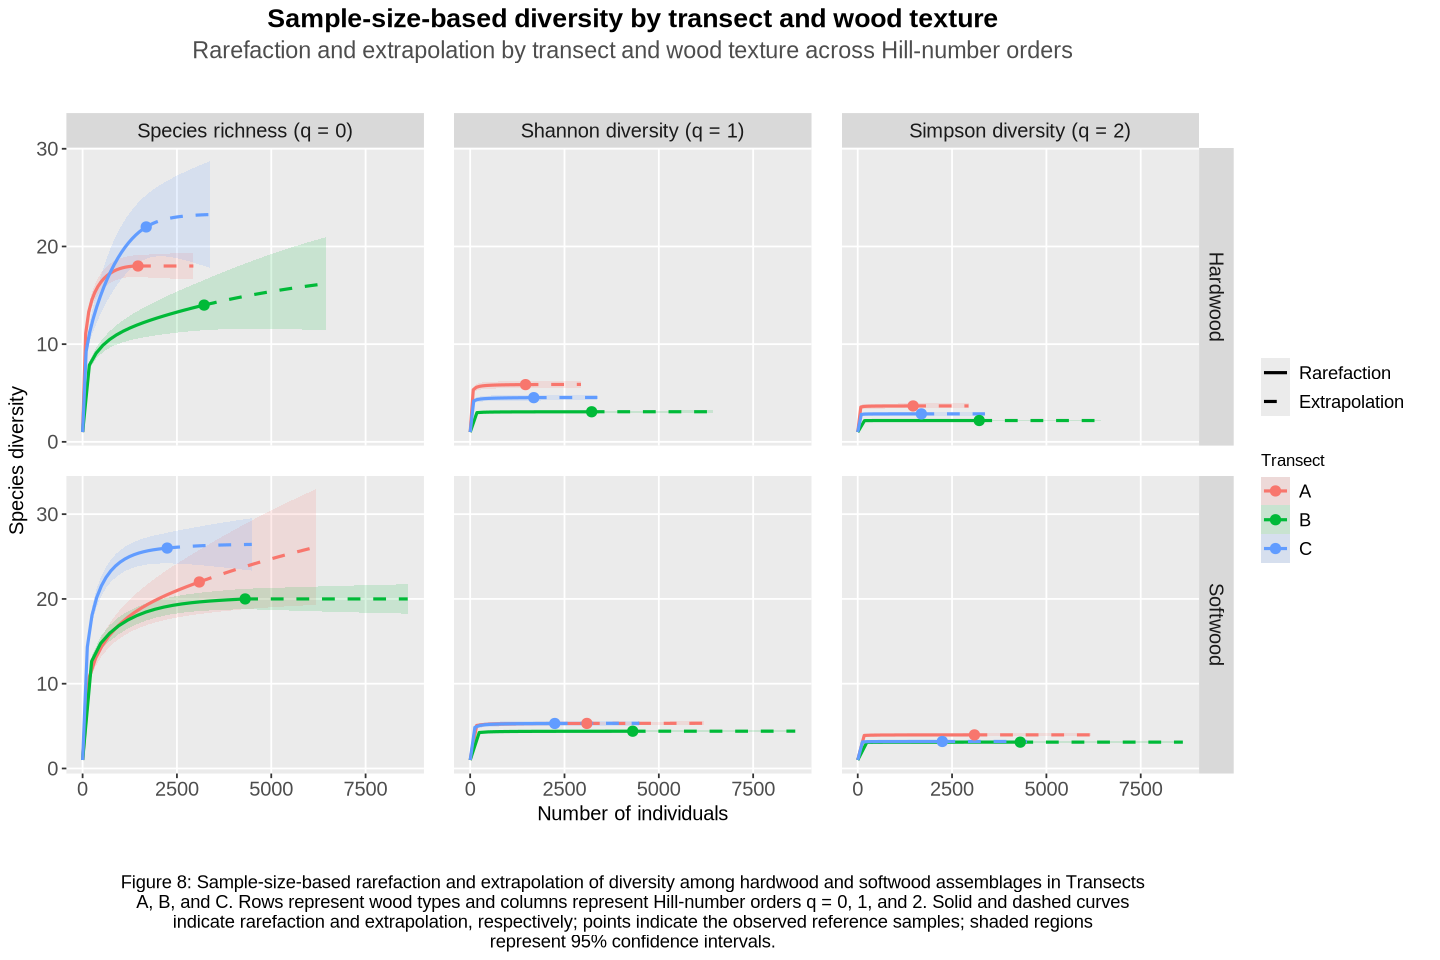

In [37]:
title_text <- paste0(
    "Sample-size-based diversity by transect and wood texture"
)

subtitle_text <- paste0(
    "Rarefaction and extrapolation by transect and wood texture across Hill-number orders"
)

caption_text <- paste0(
    "Figure 8: Sample-size-based rarefaction and extrapolation of diversity among hardwood and softwood assemblages ",
    "in Transects A, B, and C. Rows represent wood types and columns represent Hill-number orders q = 0, 1, and 2. ",
    "Solid and dashed curves indicate rarefaction and extrapolation, respectively; points indicate the observed ",
    "reference samples; shaded regions represent 95% confidence intervals."
)

y.figure3 <- ggplot(
    plot_data,
    aes(
        x = x,
        y = y,
        color = Transect,
        fill = Transect
    )
) +
    geom_ribbon(
        aes(
            ymin = y.lwr,
            ymax = y.upr,
            group = interaction(Transect, Method)
        ),
        alpha = 0.15,
        linewidth = 0
    ) +
    geom_line(
        aes(
            linetype = Method,
            group = interaction(Transect, Method)
        ),
        linewidth = 0.9
    ) +
    geom_point(
        data = observed_data,
        aes(
            x = x,
            y = y,
            color = Transect
        ),
        inherit.aes = FALSE,
        size = 2.5
    ) +
    scale_linetype_manual(
        values = c(
            "Rarefaction" = "solid",
            "Extrapolation" = "dashed"
        )
    ) +
    facet_grid(
        Wood.Texture ~ Order.q,
        scales = "free_y"
    ) +
    labs(
        x = "Number of individuals",
        y = "Species diversity",
        color = "Transect",
        fill = "Transect",
        linetype = NULL
    ) +
    make_gginext_labels_and_themes(
        title_text,
        subtitle_text,
        caption_text
    )

options(repr.plot.width = 12, repr.plot.height = 8)
y.figure3

#### Results

### 3.4. Sampling completeness (type = 2)

#### Figure 9: Sampling completeness by transect

In [38]:
# Extract sample-completeness data
plot_data <- fortify(inext, type = 2)

# Separate assemblage into transect and wood texture
plot_data <- plot_data %>%
    separate(
        Assemblage,
        into = c("Transect", "Wood.Texture"),
        sep = "-",
        remove = FALSE
    ) %>%
    mutate(
        Transect = factor(Transect, levels = c("A", "B", "C")),
        Wood.Texture = factor(Wood.Texture, levels = c("Hardwood", "Softwood"))
    )

# Preserve the observed reference points before converting "Observed" to "Rarefaction"
observed_data <- plot_data %>%
    filter(Method == "Observed")

# Treat the observed point as the end of the rarefaction curve
plot_data <- plot_data %>%
    mutate(
        Method = if_else(Method == "Observed", "Rarefaction", Method),
        Method = factor(Method, levels = c("Rarefaction", "Extrapolation"))
    )

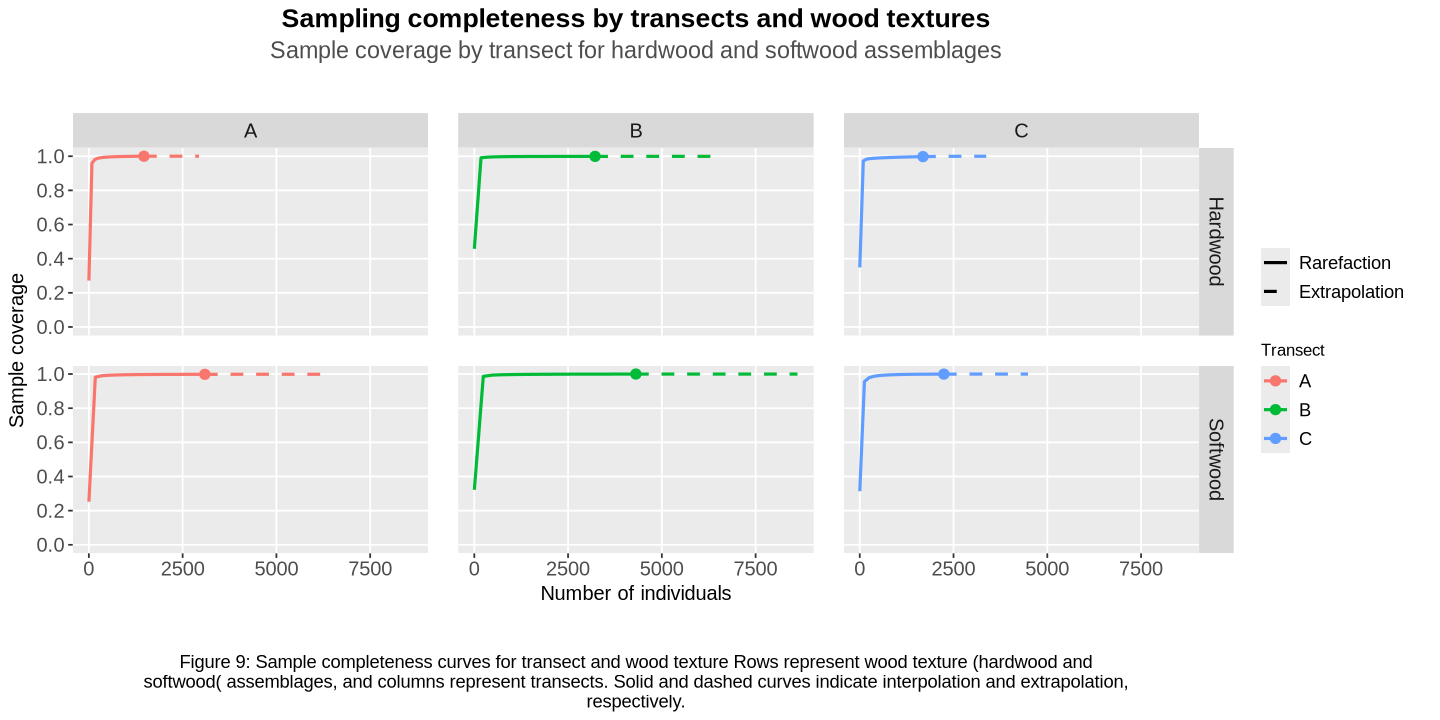

In [39]:
title_text <- paste0(
    "Sampling completeness by transects and wood textures"
)

subtitle_text <- paste0(
    "Sample coverage by transect for hardwood and softwood assemblages"
)

caption_text <- paste0(
    "Figure 9: Sample completeness curves for transect and wood texture ",
    "Rows represent wood texture (hardwood and softwood( assemblages, and columns represent transects. ",
    "Solid and dashed curves indicate interpolation and extrapolation, respectively."
)

y.figure4 <- ggplot(plot_data,
    aes(
        x = x,
        y = y,
        color = Transect,
        linetype = Method
    )) +
    geom_line(linewidth = 0.9) +
    # Observed/reference sample
    geom_point(
        data = observed_data,
        aes(
            x = x,
            y = y,
            color = Transect
        ),
        inherit.aes = FALSE,
        size = 2.5
    ) +
    # Top row = Hardwood
    # Bottom row = Softwood
    # Columns = Transects A, B, C
    facet_grid(
        Wood.Texture ~ Transect
    ) +
    scale_linetype_manual(
        values = c(
            "Rarefaction" = "solid",
            "Extrapolation" = "dashed"
        )
    ) +
    scale_y_continuous(
        limits = c(0, 1),
        breaks = seq(0, 1, 0.2)
    ) +
    labs(
        x = "Number of individuals",
        y = "Sample coverage",
        color = "Transect",
        linetype = NULL
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

options(repr.plot.width = 12, repr.plot.height = 6)
y.figure4

#### Results

### 3.5. Sample Coverage (type = 3)

In [40]:
title_text <- paste0(
    "Coverage diversity by transect and wood texture"
)

subtitle_text <- paste0(
    "Diversity estimates across Hill-number orders and sample coverage"
)

caption_text <- paste0(
    "Figure 5: Coverage diversity curves for by transect and wood texture. ",
    "Rows represent hardwood and softwood assemblages, columns represent transects, ",
    "and curves correspond to Hill-number orders q = 0, 1, and 2."
)

y.figure5a <- ggplot(plot_data, aes(x = SC, y = qD)) +
    # Coverage-based diversity curves
    geom_line(
        aes(
            color = Order.q,
            linetype = Method,
            group = interaction(Order.q, Method)
        ),
        linewidth = 0.9
    ) +
    # Observed/reference points
    geom_point(
        data = observed_data,
        aes(
            x = SC,
            y = qD,
            color = Order.q
        ),
        inherit.aes = FALSE,
        size = 2.3
    ) +
    # Hardwood on top
    # Softwood on bottom
    # Transects A, B, C across columns
    facet_grid(
        Wood.Texture ~ Transect,
        scales = "free_y",
        labeller = labeller(
            Transect = c(
                "A" = "Transect A",
                "B" = "Transect B",
                "C" = "Transect C"
            )
        )
    ) +
    scale_linetype_manual(
        values = c(
            "Rarefaction" = "solid",
            "Extrapolation" = "dashed"
        )
    ) +
    labs(
        x = "Sample coverage",
        y = "Species diversity",
        color = "Hill-number order",
        linetype = NULL
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

options(repr.plot.width = 12, repr.plot.height = 8)
y.figure5a

ERROR while rich displaying an object: Error in `geom_line()`:
! Problem while computing aesthetics.
ℹ Error occurred in the 1st layer.
Caused by error:
! object 'SC' not found

Traceback:
1. sapply(x, f, simplify = simplify)
2. lapply(X = X, FUN = FUN, ...)
3. FUN(X[[i]], ...)
4. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
5. tryCatchList(expr, classes, parentenv, handlers)
6. tryCatchOne(expr, names, parentenv, handlers[[1L]])
7. doTryCatch(return(expr), name, parentenv, handler)
8. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .     

#### Figure 10: Coverage-based diversity across Hill-number orders

In [41]:
title_text <- paste0(
    "Coverage diversity by transect and wood texture"
)

subtitle_text <- paste0(
    "Comparison of diversity by transect and wood texture across Hill-number orders and sample coverage"
)

caption_text <- paste0(
    "Figure 10: Coverage diversity by transect and wood texture (hardwood and softwood). ",
    "Rows represent hardwood and softwood assemblages, while columns show Hill-number orders ",
    "q = 0 (species richness), q = 1 (Shannon diversity), and q = 2 (Simpson diversity). ",
    "Curves show how species diversity varies with sample coverage within each wood texture."
)

y.figure5b <- ggplot(plot_data, aes(x = SC, y = qD)) +
    # Coverage-based diversity curves
    geom_line(
        aes(
            color = Transect,
            linetype = Method,
            group = interaction(Transect, Method)
        ),
        linewidth = 0.9
    ) +
    # Observed/reference points
    geom_point(
        data = observed_data,
        aes(
            x = SC,
            y = qD,
            color = Transect
        ),
        inherit.aes = FALSE,
        size = 2.3
    ) +
    # Hardwood on top, Softwood on bottom
    # Hill numbers across columns
    facet_grid(
        Wood.Texture ~ Order.q,
        scales = "free_y"
    ) +
    scale_linetype_manual(
        values = c(
            "Rarefaction" = "solid",
            "Extrapolation" = "dashed"
        )
    ) +
    labs(
        x = "Sample coverage",
        y = "Species diversity",
        color = "Transect",
        linetype = NULL
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

options(repr.plot.width = 12, repr.plot.height = 8)
y.figure5b

ERROR while rich displaying an object: Error in `geom_line()`:
! Problem while computing aesthetics.
ℹ Error occurred in the 1st layer.
Caused by error:
! object 'SC' not found

Traceback:
1. sapply(x, f, simplify = simplify)
2. lapply(X = X, FUN = FUN, ...)
3. FUN(X[[i]], ...)
4. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
5. tryCatchList(expr, classes, parentenv, handlers)
6. tryCatchOne(expr, names, parentenv, handlers[[1L]])
7. doTryCatch(return(expr), name, parentenv, handler)
8. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .     

#### Results

## 4. Diversity by Transect and Wood Type

In [42]:
saproxylic_df <- cbind(environment_df$Transect, environment_df$Wood.Type, saproxylic_community_df)
names(saproxylic_df)[1:2] =  c("Transect", "Wood.Type")         # Environment columns as Site
saproxylic_df <- saproxylic_df %>%
    group_by(Transect, Wood.Type) %>%
    summarise(
        across(3:last_col(), sum),                              # OTU counts
        .groups = "drop"
      ) %>%
    mutate(Site = paste(Transect,"-",Wood.Type, sep="")) %>%    # New site column
    relocate(Site) %>%
    select(-Transect, -Wood.Type)                               # Remove environment columns

site_names = saproxylic_df$Site

saproxylic_df <- saproxylic_df %>%
    select(-Site)
saproxylic_df <- as.data.frame(t(saproxylic_df))
names(saproxylic_df) <- site_names

head(saproxylic_df)

,A-Birch,A-Pine,A-Spruce,B-Birch,B-Pine,B-Spruce,C-Birch,C-Pine,C-Spruce
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Ascocoryne,0,0,0,1,67,2,1,35,1
Atheliachaete,0,0,0,0,3,0,0,0,0
Botryobasidium,0,0,0,0,6,0,0,0,0
Ceraceomyces,42,3,36,1,0,3,928,19,1
Cistella,4,5,5,0,0,0,0,9,31
Claussenomyces,0,0,0,0,0,0,0,0,5


In [43]:
# Prepare the abundance list for iNEXT
abundance_list <- lapply(saproxylic_df, function(x) x[x != 0])
abundance_list

$`A-Birch`
 [1]  42   4  13   3 167   2   2   5  31  24  77  40  51 296   6  10  19 676

$`A-Pine`
 [1]   3   5  17 212   1 528   4  15   1  28   2  41   3   2   1   4 894

$`A-Spruce`
 [1]  36   5   3   1   3 221  10  12   1   1   1  94   6  13  34 517 374

$`B-Birch`
 [1]    1    1    5   71   86  118    1    6  102  771   11   16    2 2029

$`B-Pine`
 [1]   67    3    6    3   41  108   24   29   16    2   31  379    7  422    1
[16] 1123

$`B-Spruce`
 [1]    2    3    2   49    5   10   27    1    3    2    5   24 1101   38    4
[16]    3  767

$`C-Birch`
 [1]   1 928  91   2 196  49 279   2   2   3   1  54  28   2   2  27   2   1   3
[20]   4   8   1

$`C-Pine`
 [1]   35   19    9    2    8    8  536    1    4    4   10    7   14    5    9
[16]   17   73 1056    2    3   59    3

$`C-Spruce`
 [1]   1   1  31   5  46   3 118   1  46  11   2  13   8   2   3  53   3   2   9

In [44]:
# computes rarefaction (interpolation) and extrapolation (prediction) sampling curves for biodiversity 
# standard comparisons across communities using Hill numbers 
# (q=0 for species richness, q=1 for Shannon diversity, and q=2 for Simpson diversity) based on sample size or sample coverage.
inext <- iNEXT(abundance_list, q=c(0, 1, 2), datatype="abundance")

### 4.1. Abundance, observed richness, and sample coverage

In [45]:
data_info <- inext$DataInfo %>%
    separate_wider_delim(
        cols = Assemblage, 
        delim = "-", 
        names = c("Transect", "Wood.Type"),
        cols_remove = FALSE
    ) %>%
    mutate(
        Description = recode_values(
            Transect,
            from = c("A", "B", "C"),
            to = c("conifer forest with access of reindeer", 
                   "conifer forest without access of reindeer", 
                   "broadleaf forest and accessed to tourists"),
            default = Transect
        ),
        Sample_Coverage = paste0(SC * 100, "%")
    ) %>%
    select(
        Assemblage,
        Transect,
        Description,
        Wood.Type,
        n,
        S.obs,
        Sample_Coverage
    )

data_info

Assemblage,Transect,Description,Wood.Type,n,S.obs,Sample_Coverage
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
A-Birch,A,conifer forest with access of reindeer,Birch,1468,18,100%
A-Pine,A,conifer forest with access of reindeer,Pine,1761,17,99.83%
A-Spruce,A,conifer forest with access of reindeer,Spruce,1332,17,99.7%
B-Birch,B,conifer forest without access of reindeer,Birch,3220,14,99.91%
B-Pine,B,conifer forest without access of reindeer,Pine,2262,16,99.96%
B-Spruce,B,conifer forest without access of reindeer,Spruce,2046,17,99.95%
C-Birch,C,broadleaf forest and accessed to tourists,Birch,1686,22,99.76%
C-Pine,C,broadleaf forest and accessed to tourists,Pine,1884,22,99.95%
C-Spruce,C,broadleaf forest and accessed to tourists,Spruce,358,19,99.17%


#### Table 1: Abundance and observed species richness

In [46]:
caption_text <- paste0(
    "Table 1: Abundance, observed species richness, and sample coverage ",
    "by transect and wood type."
)

z.table1 <- data_info %>%
    select (
        Transect,
        Description,
        Wood.Type,
        n,
        S.obs,
        Sample_Coverage
    ) %>%
    gt() %>% 
    cols_label(
        Transect = md("**Transect**"),
        Description = md("**Description**"),
        Wood.Type = md("**Wood Type**"),
        n = md("**Abundance**"),
        S.obs = md("**Observed Richness**"),
        Sample_Coverage = md("**Sample Coverage**")
    ) %>%
    cols_align(
        align = "center",
        columns = 1
    ) %>%
    tab_style(
        style = cell_text(align = "center"),
        locations = cells_column_labels(columns = everything())
    ) %>%
    tab_caption(
        caption = md(caption_text)
    ) 

In [47]:
z.table1 %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html()

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 1: Abundance, observed species richness, and sample coverage by transect and wood type. <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_center" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Transect" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Description" align="center" bgcolor="#FFFFFF" valign="bottom"> Description 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Wood.Type" align="center" bgcolor="#FFFFFF" valign="bottom"> Wood Type 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="n" align="center" bgcolor="#FFFFFF" valign="bottom"> Abundance 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tab

#### Figure 1: Abundance distribution across transects and wood types

In [48]:
a_data_info <- data_info %>%
    filter(Transect == "A") %>%
    mutate(
        percentage = n / sum(n) * 100,
        label = paste0(Wood.Type, "\n(", round(percentage, 1), "%)")
    )

a_data_info

Assemblage,Transect,Description,Wood.Type,n,S.obs,Sample_Coverage,percentage,label
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<chr>
A-Birch,A,conifer forest with access of reindeer,Birch,1468,18,100%,32.18592,Birch (32.2%)
A-Pine,A,conifer forest with access of reindeer,Pine,1761,17,99.83%,38.60995,Pine (38.6%)
A-Spruce,A,conifer forest with access of reindeer,Spruce,1332,17,99.7%,29.20412,Spruce (29.2%)


In [49]:
b_data_info <- data_info %>%
    filter(Transect == "B") %>%
    mutate(
        percentage = n / sum(n) * 100,
        label = paste0(Wood.Type, "\n(", round(percentage, 1), "%)")
    )

b_data_info

Assemblage,Transect,Description,Wood.Type,n,S.obs,Sample_Coverage,percentage,label
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<chr>
B-Birch,B,conifer forest without access of reindeer,Birch,3220,14,99.91%,42.77365,Birch (42.8%)
B-Pine,B,conifer forest without access of reindeer,Pine,2262,16,99.96%,30.04782,Pine (30%)
B-Spruce,B,conifer forest without access of reindeer,Spruce,2046,17,99.95%,27.17853,Spruce (27.2%)


In [50]:
c_data_info <- data_info %>%
    filter(Transect == "C") %>%
    mutate(
        percentage = n / sum(n) * 100,
        label = paste0(Wood.Type, "\n(", round(percentage, 1), "%)")
    )

c_data_info

Assemblage,Transect,Description,Wood.Type,n,S.obs,Sample_Coverage,percentage,label
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<chr>
C-Birch,C,broadleaf forest and accessed to tourists,Birch,1686,22,99.76%,42.922607,Birch (42.9%)
C-Pine,C,broadleaf forest and accessed to tourists,Pine,1884,22,99.95%,47.963340,Pine (48%)
C-Spruce,C,broadleaf forest and accessed to tourists,Spruce,358,19,99.17%,9.114053,Spruce (9.1%)


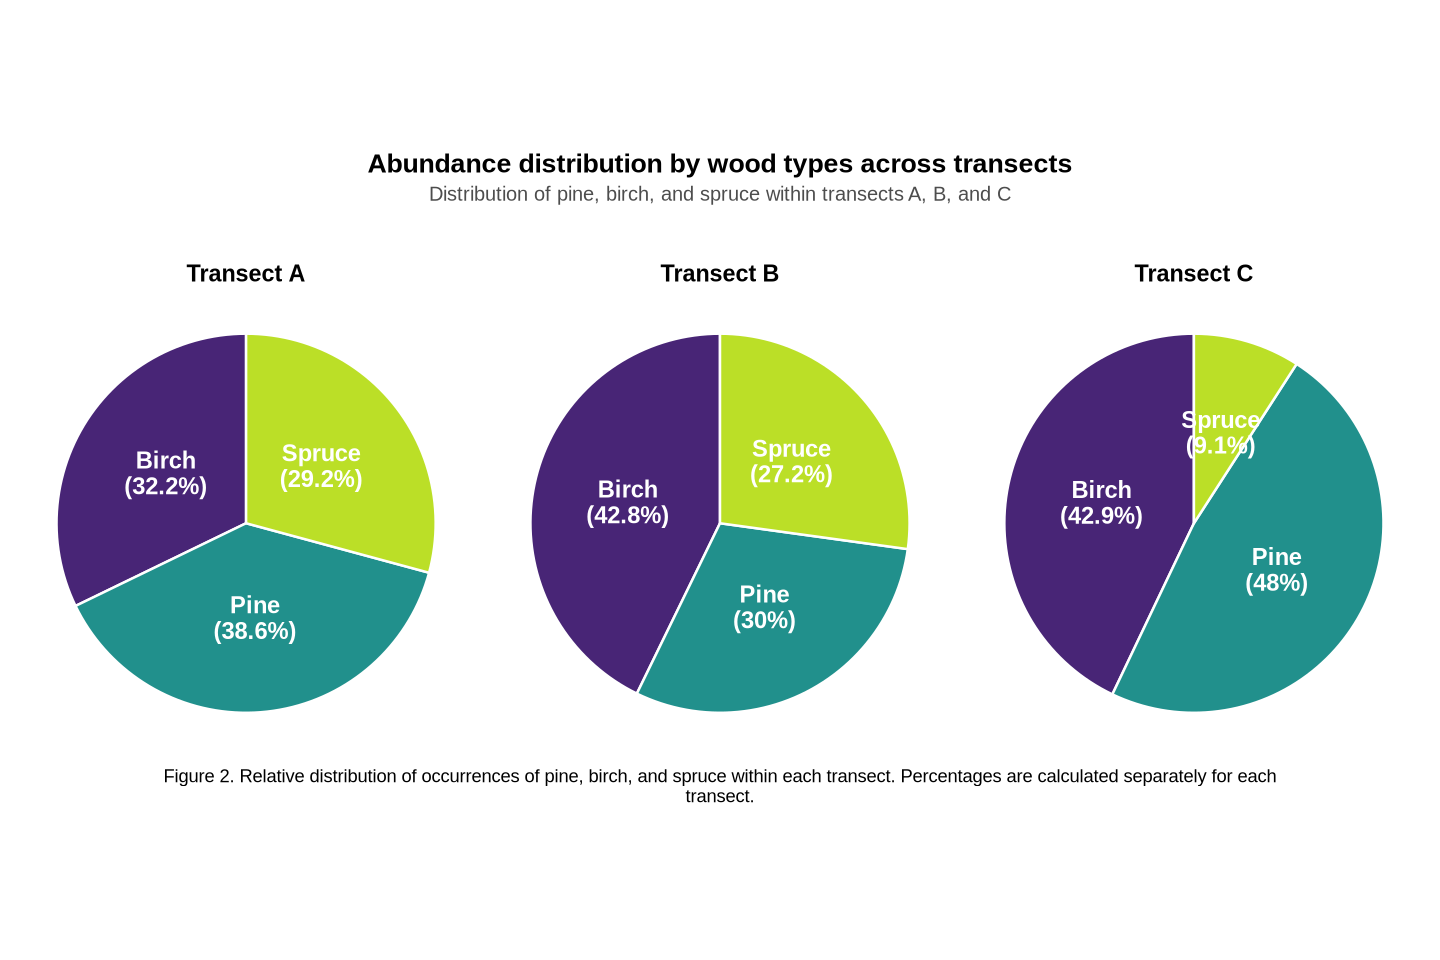

In [51]:
# How does wood-texture composition differ within each transect?
a_pie_chart <- make_pie_chart(a_data_info, a_data_info$percentage, a_data_info$Wood.Type, a_data_info$label) +
    labs(title = "Transect A") +
    theme(
        plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
        legend.position = "none"
    )

b_pie_chart <- make_pie_chart(b_data_info, b_data_info$percentage, b_data_info$Wood.Type, b_data_info$label) +
    labs(title = "Transect B") +
    theme(
        plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
        legend.position = "none"
    )

c_pie_chart <- make_pie_chart(c_data_info, c_data_info$percentage, c_data_info$Wood.Type, c_data_info$label) +
    labs(title = "Transect C") +
    theme(
        plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
        legend.position = "none"
    )

caption_text <- paste0(
    "Figure 2. Relative distribution of occurrences of pine, birch, and spruce ",
    "within each transect. Percentages are calculated separately for each transect."
)

title_and_caption <- plot_annotation(
    title = "Abundance distribution by wood types across transects",
    subtitle = "Distribution of pine, birch, and spruce within transects A, B, and C",
    caption = str_wrap(caption_text, width = 150),
    theme = theme(
        plot.title = element_text(size = 16, face = "bold", hjust = 0.5),
        plot.subtitle = element_text(hjust = 0.5, size = 12, color = "grey30", margin = margin(b=30)),
        plot.caption = element_text(hjust = 0.5, size = 11)
    )
)

combined_pie_chart <-
    a_pie_chart + b_pie_chart + c_pie_chart + title_and_caption    

z.figure1 <- combined_pie_chart
z.figure1

### 4.2. Observed and estimated diversity

In [52]:
asy_est <- inext$AsyEst %>%
    separate_wider_delim(
        cols = Assemblage, 
        delim = "-", 
        names = c("Transect", "Wood.Types"),
        cols_remove = FALSE
    ) %>%
    mutate(
        `95% CI` = sprintf("%.2f – %.2f", LCL, UCL),
        Diversity_q = recode_values(
            Diversity,
            from = c("Species richness", "Shannon diversity", "Simpson diversity"),
            to = c("0", "1", "2"),
            default = Diversity
        )
    ) 

asy_est

Transect,Wood.Types,Assemblage,Diversity,Observed,Estimator,s.e.,LCL,UCL,95% CI,Diversity_q
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
A,Birch,A-Birch,Species richness,18.000000,18.000000,1.15897974,18.000000,20.271559,18.00 – 20.27,0
A,Birch,A-Birch,Shannon diversity,5.858099,5.892891,0.18471443,5.530858,6.254925,5.53 – 6.25,1
A,Birch,A-Birch,Simpson diversity,3.673528,3.680235,0.12689910,3.431518,3.928953,3.43 – 3.93,2
A,Pine,A-Pine,Species richness,17.000000,19.248722,4.85478213,17.000000,28.763920,17.00 – 28.76,0
A,Pine,A-Pine,Shannon diversity,3.644149,3.664706,0.09584906,3.476845,3.852567,3.48 – 3.85,1
A,Pine,A-Pine,Simpson diversity,2.754033,2.756780,0.05884971,2.641437,2.872124,2.64 – 2.87,2
A,Spruce,A-Spruce,Species richness,17.000000,22.995495,7.10231966,17.000000,36.915786,17.00 – 36.92,0
A,Spruce,A-Spruce,Shannon diversity,5.048142,5.092011,0.14180634,4.814076,5.369946,4.81 – 5.37,1
A,Spruce,A-Spruce,Simpson diversity,3.792779,3.800754,0.09765594,3.609352,3.992156,3.61 – 3.99,2


#### Table 2: Observed and asymptotic Hill diversity estimates

In [53]:
# Create a publish-ready table of the asymptotic Hill diversity estimates
caption_text <- paste0(
    "Table 2: Observed and asymptotic Hill diversity estimates for saproxylic fungal ",
    "assemblages across Transects A, B, and C and wood types Reported values ",
    "include observed diversity, estimated asymptotic diversity, and 95% confidence ",
    "intervals for q = 0, 1, and 2."
)

z.table2 <- asy_est %>%
    select (
        Transect,
        Wood.Types,
        Diversity_q,
        Observed,
        Estimator,
        `95% CI`,
    ) %>%
    gt() %>% 
    cols_label(
        Transect = md("**Transect**"),
        Wood.Types = md("**Wood Types**"),
        Diversity_q = md("**Diversity**"),
        Observed = md("**Observed**"),
        Estimator = md("**Asymptotic estimate**"),
        `95% CI` = md("**95% CI**"),
    ) %>%
    cols_align(
        align = "center",
        columns = 1
    ) %>%
    cols_align(
        align = "right",
        columns = 5
    ) %>%
    fmt(
        columns = Diversity_q,
        fns = function(x) {
            recode_values(x,
                "0" ~ "Species richness (q=0)", 
                "1" ~ "Shannon diversity (q=1)", 
                "2" ~ "Simpson diversity (q=2)"
            )
        }
    ) %>%
    fmt_number(
        columns = where(is.numeric),
        decimals = 2
    ) %>%
    tab_style(
        style = cell_text(align = "center"),
        locations = cells_column_labels(columns = everything())
    ) %>%
    tab_caption(
        caption = md(caption_text)
    ) 

In [54]:
z.table2 %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html()

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 2: Observed and asymptotic Hill diversity estimates for saproxylic fungal assemblages across Transects A, B, and C and wood types Reported values include observed diversity, estimated asymptotic diversity, and 95% confidence intervals for q = 0, 1, and 2. <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_center" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Transect" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Wood.Types" align="center" bgcolor="#FFFFFF" valign="bottom"> Wood Types 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="Diversity_q" align="center" bgcolor="#FFFFFF" valign="bottom"> Diversity 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="Observed" align="center" bgcolor="#FFFFFF" valign="bottom"> Observed 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-sty

### 4.3. Sample size diversity (type = 1)

In [55]:
# Convert iNEXT output to plotting data for type = 1
plot_data <- fortify(inext, type=1)

# Split Assemblage into Transect and Wood Types
plot_data <- plot_data %>%
    separate(
        Assemblage,
        into = c("Transect", "Wood.Type"),
        sep = "-",
        remove = FALSE
    ) %>%
    mutate(
        Transect = factor(Transect, levels = c("A", "B", "C")),
        Wood.Type = factor(Wood.Type, levels = c("Birch", "Pine", "Spruce")),
        Order.q = factor(
            Order.q,
            levels = c(0, 1, 2),
            labels = c(
                "Species richness (q = 0)",
                "Shannon diversity (q = 1)",
                "Simpson diversity (q = 2)"
            )
        )
    )

# Preserve the observed reference points
observed_data <- plot_data %>%
    filter(Method == "Observed")
     

#### Figure 3: Sample size diversity by transect

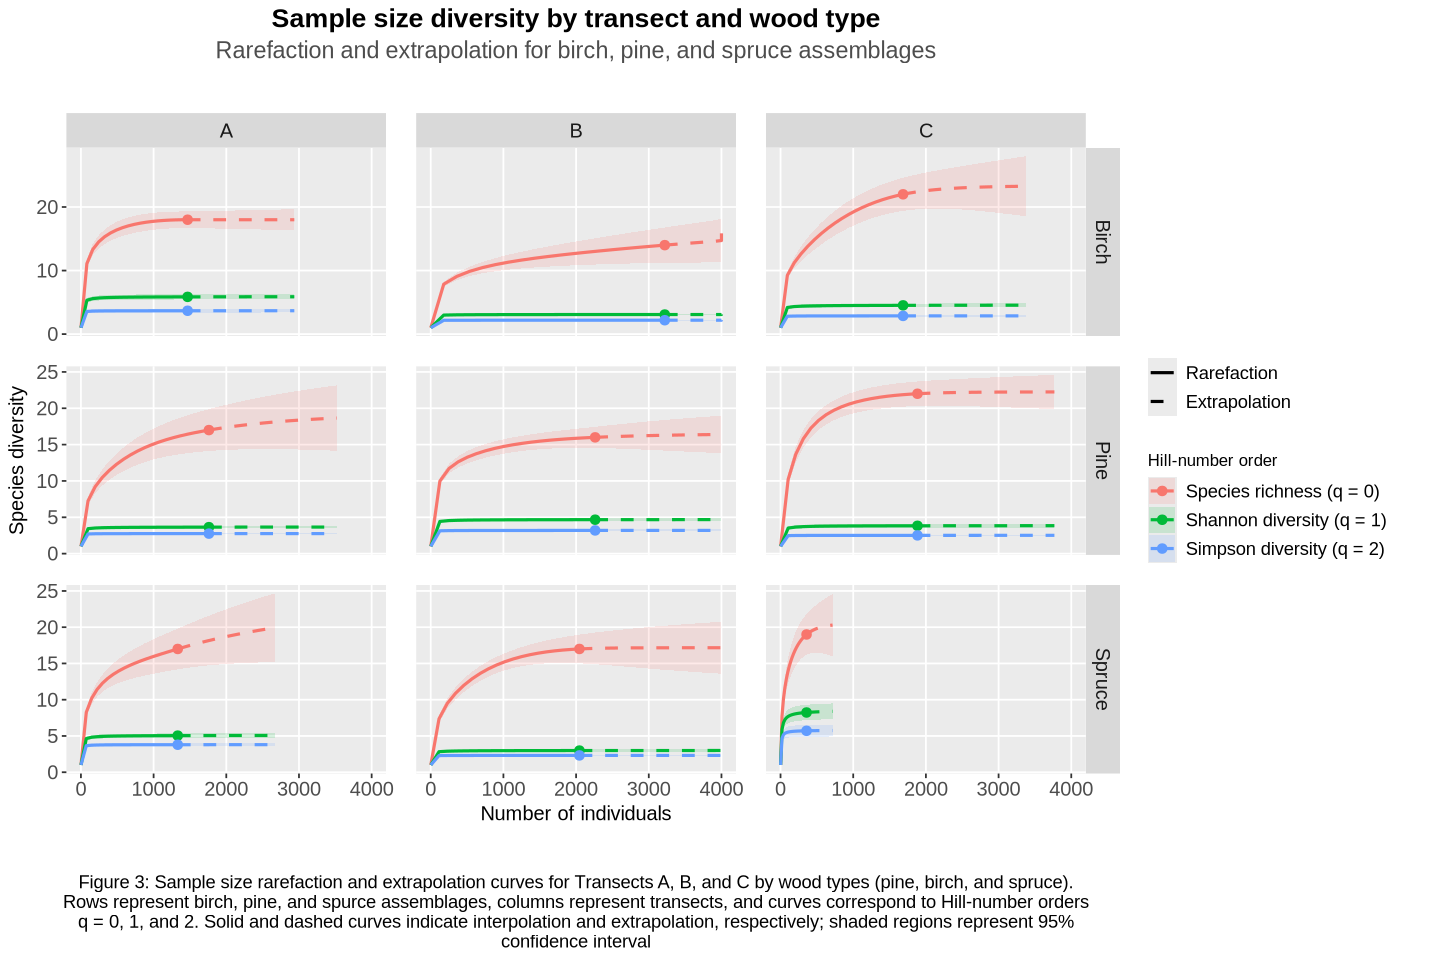

In [56]:
# Treat the observed point as the end of the rarefaction curve
plot_data <- plot_data %>%
    mutate(
        Method = if_else(Method == "Observed", "Rarefaction", Method),
        Method = factor(Method, levels = c("Rarefaction", "Extrapolation"))
    )

title_text <- paste0(
    "Sample size diversity by transect and wood type"
)

subtitle_text <- paste0(
    "Rarefaction and extrapolation for birch, pine, and spruce assemblages"
)

caption_text <- paste0(
    "Figure 3: Sample size rarefaction and extrapolation curves for Transects A, B, and C by ",
    "wood types (pine, birch, and spruce). Rows represent birch, pine, and spurce assemblages, ",
    "columns represent transects, and curves correspond to Hill-number orders q = 0, 1, and 2. ",
    "Solid and dashed curves indicate interpolation and extrapolation, respectively; shaded ",
    "regions represent 95% confidence interval"
)

z.figure3a <- ggplot(plot_data, aes(x = x, y = y)) +
    # 95% confidence intervals
    geom_ribbon(
        aes(
            ymin = y.lwr,
            ymax = y.upr,
            fill = Order.q,
            group = Order.q
        ),
        alpha = 0.15,
        color = NA
    ) +
    # Rarefaction/extrapolation curves
    geom_line(
        aes(
            color = Order.q,
            linetype = Method,
            group = interaction(Order.q, Method)
        ),
        linewidth = 0.9
    ) +
    # Observed/reference points
    geom_point(data = observed_data,
        aes(x = x, y = y, color = Order.q),
        inherit.aes = FALSE,
        size = 2.3
    ) +
    # Hardwood on top, Softwood on bottom
    # Transects A, B, C across columns
    facet_grid(
        Wood.Type ~ Transect,
        scales = "free_y"
    ) +
    scale_linetype_manual(
        values = c(
            "Rarefaction" = "solid",
            "Extrapolation" = "dashed"
        )
    ) + 
    scale_x_continuous(limits = c(0, 4000), oob=squish) +
    labs(
        x = "Number of individuals",
        y = "Species diversity",
        color = "Hill-number order",
        fill = "Hill-number order",
        linetype = NULL,
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)            

options(repr.plot.width = 12, repr.plot.height = 8)
z.figure3a

#### Figure 3: Sample size diversity across Hill-number orders

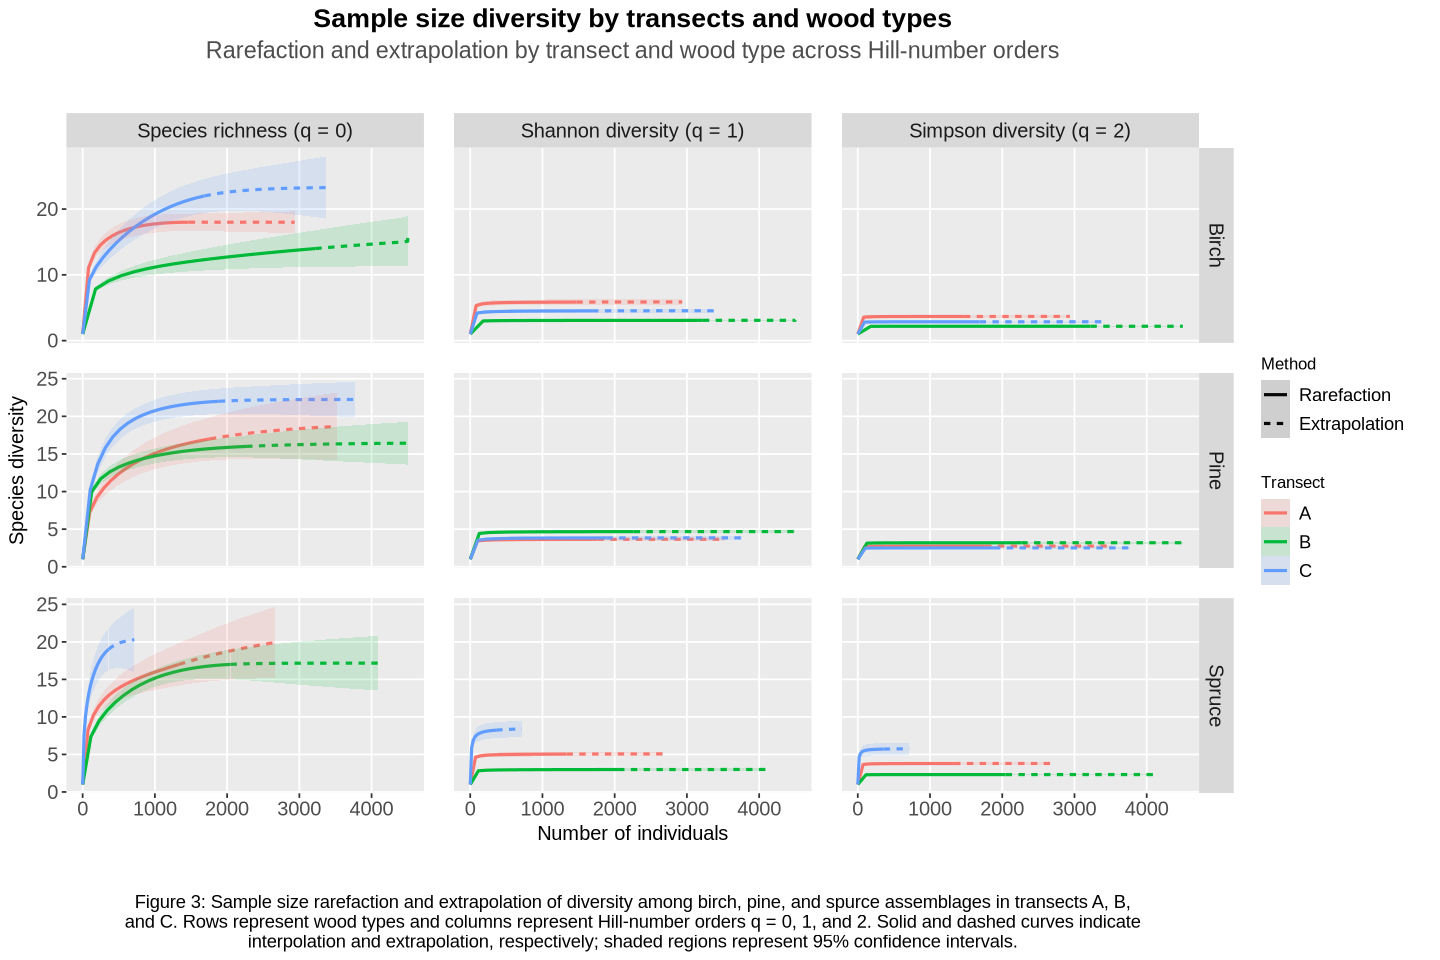

In [57]:
title_text <- paste0(
    "Sample size diversity by transects and wood types"
)

subtitle_text <- paste0(
    "Rarefaction and extrapolation by transect and wood type across Hill-number orders"
)

caption_text <- paste0(
    "Figure 3: Sample size rarefaction and extrapolation of diversity among birch, pine, and spurce assemblages ",
    "in transects A, B, and C. Rows represent wood types and columns represent Hill-number orders q = 0, 1, and 2. ",
    "Solid and dashed curves indicate interpolation and extrapolation, respectively; shaded regions represent 95% ",
    "confidence intervals."
)

z.figure3b <- ggplot(plot_data,
    aes(x = x, 
        y = y,
        color = Transect,
        fill = Transect,
        linetype = Method
    )) +
    geom_line(linewidth = 0.9) +
    geom_ribbon(
        aes(ymin = y.lwr, ymax = y.upr),
        alpha = 0.15,
        linewidth = 0
    ) +
    facet_grid(
        Wood.Type ~ Order.q,
        scales = "free_y"
    ) + 
    scale_x_continuous(limits = c(0, 4500), oob=squish) +
    labs(
        x = "Number of individuals",
        y = "Species diversity",
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)  

options(repr.plot.width = 12, repr.plot.height = 8)
z.figure3b 

### 4.4. Sampling completeness (type = 2)

#### Figure 4: Sampling completeness by transect

In [58]:
# Extract sample-completeness data
plot_data <- fortify(inext, type = 2)

# Separate assemblage into transect and wood texture
plot_data <- plot_data %>%
    separate(
        Assemblage,
        into = c("Transect", "Wood.Type"),
        sep = "-",
        remove = FALSE
    ) %>%
    mutate(
        Transect = factor(Transect, levels = c("A", "B", "C")),
        Wood.Type = factor(Wood.Type, levels = c("Birch", "Pine", "Spruce"))
    )

# Preserve the observed reference points before converting "Observed" to "Rarefaction"
observed_data <- plot_data %>%
    filter(Method == "Observed")

# Treat the observed point as the end of the rarefaction curve
plot_data <- plot_data %>%
    mutate(
        Method = if_else(Method == "Observed", "Rarefaction", Method),
        Method = factor(Method, levels = c("Rarefaction", "Extrapolation"))
    )

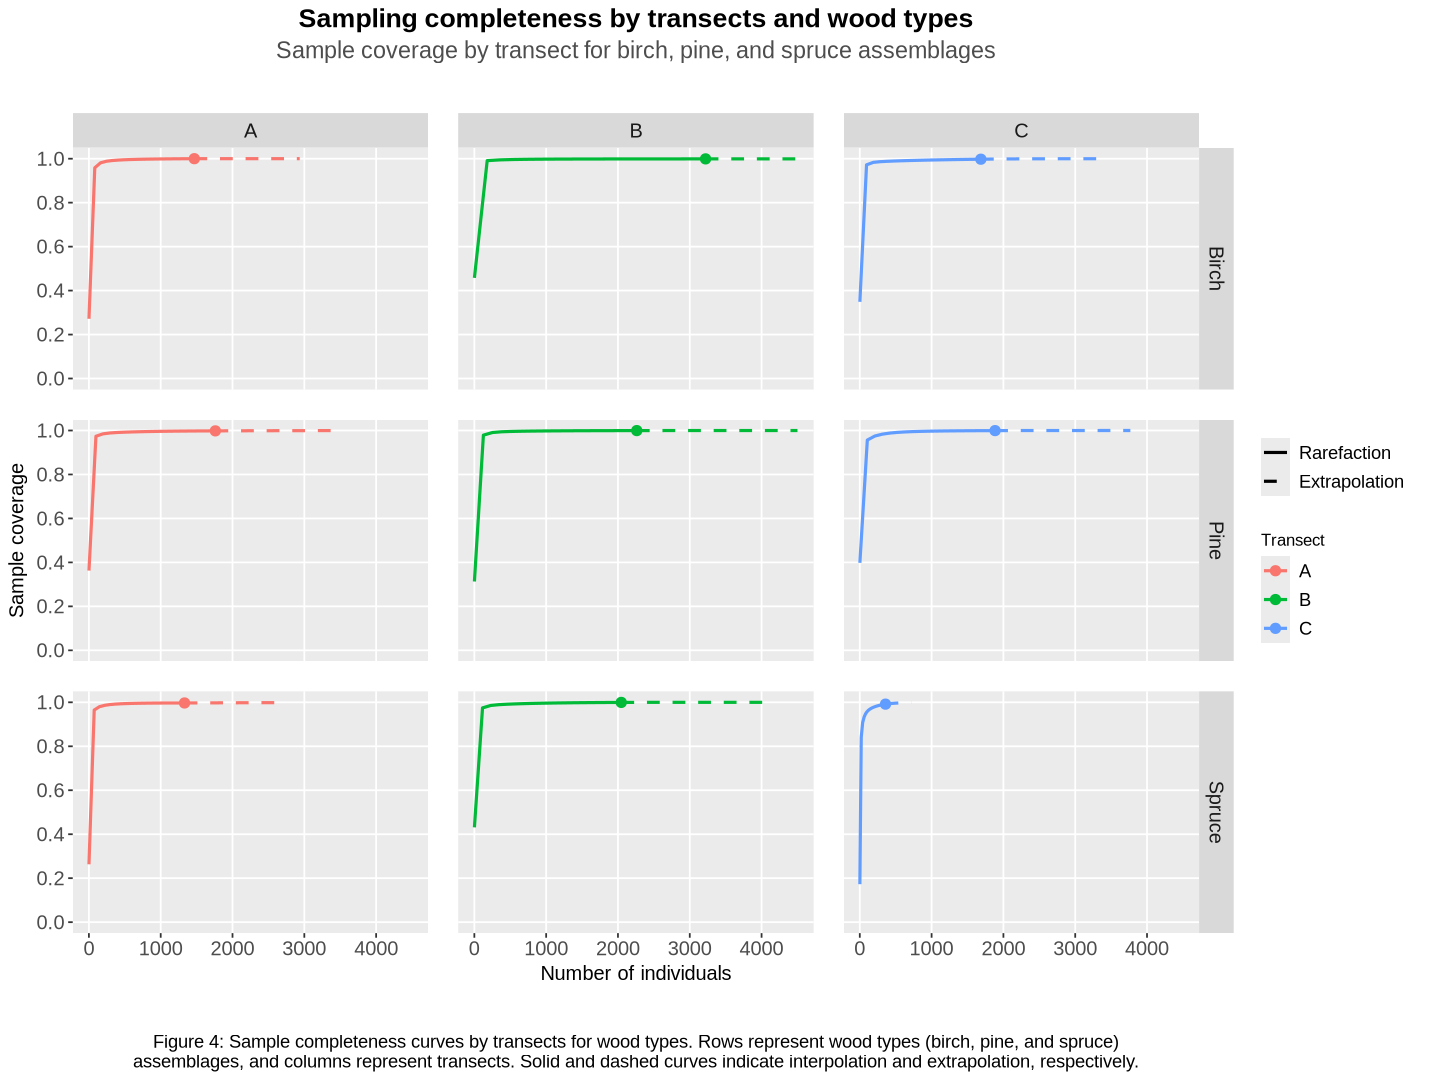

In [59]:
title_text <- paste0(
    "Sampling completeness by transects and wood types"
)

subtitle_text <- paste0(
    "Sample coverage by transect for birch, pine, and spruce assemblages"
)

caption_text <- paste0(
    "Figure 4: Sample completeness curves by transects for wood types. ",
    "Rows represent wood types (birch, pine, and spruce) assemblages, and columns represent transects. ",
    "Solid and dashed curves indicate interpolation and extrapolation, respectively."
)

z.figure4 <- ggplot(plot_data,
    aes(
        x = x,
        y = y,
        color = Transect,
        linetype = Method
    )) +
    geom_line(linewidth = 0.9) +
    # Observed/reference sample
    geom_point(
        data = observed_data,
        aes(
            x = x,
            y = y,
            color = Transect
        ),
        inherit.aes = FALSE,
        size = 2.5
    ) +
    # Top row = Hardwood
    # Bottom row = Softwood
    # Columns = Transects A, B, C
    facet_grid(
        Wood.Type ~ Transect
    ) +
    scale_linetype_manual(
        values = c(
            "Rarefaction" = "solid",
            "Extrapolation" = "dashed"
        )
    ) +
    scale_x_continuous(limits = c(0, 4500), oob=squish) +
    scale_y_continuous(
        limits = c(0, 1),
        breaks = seq(0, 1, 0.2)
    ) +
    labs(
        x = "Number of individuals",
        y = "Sample coverage",
        color = "Transect",
        linetype = NULL
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

options(repr.plot.width = 12, repr.plot.height = 9)
z.figure4

### 4.5. Sample Coverage (type = 3)

In [60]:
# Convert iNEXT output to plotting data for type = 1
plot_data <- fortify(inext, type=1)

# Split Assemblage into Transect and Wood Types
plot_data <- plot_data %>%
    separate(
        Assemblage,
        into = c("Transect", "Wood.Type"),
        sep = "-",
        remove = FALSE
    ) %>%
    mutate(
        Transect = factor(Transect, levels = c("A", "B", "C")),
        Wood.Type = factor(Wood.Type, levels = c("Birch", "Pine", "Spruce")),
        Order.q = factor(
            Order.q,
            levels = c(0, 1, 2),
            labels = c(
                "Species richness (q = 0)",
                "Shannon diversity (q = 1)",
                "Simpson diversity (q = 2)"
            )
        )
    )

# Preserve the observed reference points
observed_data <- plot_data %>%
    filter(Method == "Observed")

#### Figure 5: Coverage-based diversity by transect

In [61]:
# Use the actual coverage-based iNEXT estimates
plot_data <- inext$iNextEst$coverage_based

# Split Assemblage into Transect and Wood Texture
plot_data <- plot_data %>%
    separate(
        Assemblage,
        into = c("Transect", "Wood.Type"),
        sep = "-",
        remove = FALSE
    ) %>%
    mutate(
        Transect = factor(
            Transect,
            levels = c("A", "B", "C")
        ),
        Wood.Type = factor(
            Wood.Type,
            levels = c("Birch", "Pine", "Spruce")
        ),
        Order.q = factor(
            Order.q,
            levels = c(0, 1, 2),
            labels = c(
                "Species richness (q = 0)",
                "Shannon diversity (q = 1)",
                "Simpson diversity (q = 2)"
            )
        )
    )

# Preserve observed/reference points
observed_data <- plot_data %>%
    filter(Method == "Observed")

# Treat observed point as the end of the rarefaction curve
plot_data <- plot_data %>%
    mutate(
        Method = if_else(Method == "Observed", "Rarefaction", Method),
        Method = factor(Method, levels = c("Rarefaction", "Extrapolation"))
    )

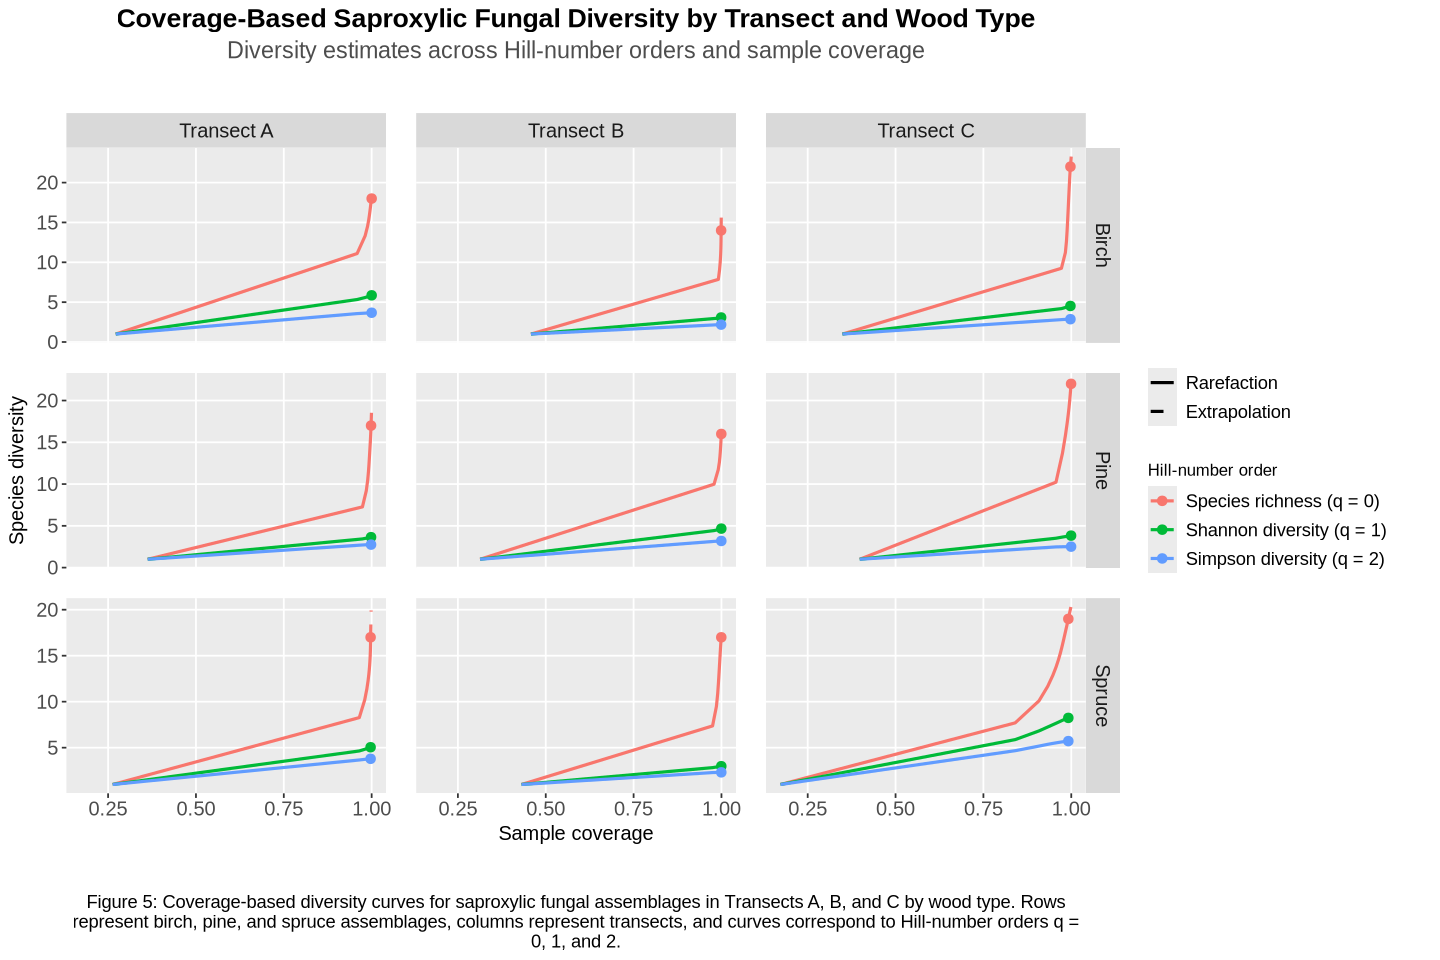

In [62]:
title_text <- paste0(
    "Coverage-Based Saproxylic Fungal Diversity by Transect and Wood Type"
)

subtitle_text <- paste0(
    "Diversity estimates across Hill-number orders and sample coverage"
)

caption_text <- paste0(
    "Figure 5: Coverage-based diversity curves for saproxylic fungal assemblages ",
    "in Transects A, B, and C by wood type. Rows represent birch, pine, and spruce ",
    "assemblages, columns represent transects, and curves correspond to Hill-number ",
    "orders q = 0, 1, and 2."
)

z.figure5a <- ggplot(plot_data, aes(x = SC, y = qD)) +
    # Coverage-based diversity curves
    geom_line(
        aes(
            color = Order.q,
            linetype = Method,
            group = interaction(Order.q, Method)
        ),
        linewidth = 0.9
    ) +
    # Observed/reference points
    geom_point(
        data = observed_data,
        aes(
            x = SC,
            y = qD,
            color = Order.q
        ),
        inherit.aes = FALSE,
        size = 2.3
    ) +
    # Hardwood on top
    # Softwood on bottom
    # Transects A, B, C across columns
    facet_grid(
        Wood.Type ~ Transect,
        scales = "free_y",
        labeller = labeller(
            Transect = c(
                "A" = "Transect A",
                "B" = "Transect B",
                "C" = "Transect C"
            )
        )
    ) +
    scale_linetype_manual(
        values = c(
            "Rarefaction" = "solid",
            "Extrapolation" = "dashed"
        )
    ) +
    labs(
        x = "Sample coverage",
        y = "Species diversity",
        color = "Hill-number order",
        linetype = NULL
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

options(repr.plot.width = 12, repr.plot.height = 8)
z.figure5a

#### Figure 5: Coverage-based diversity across Hill-number orders

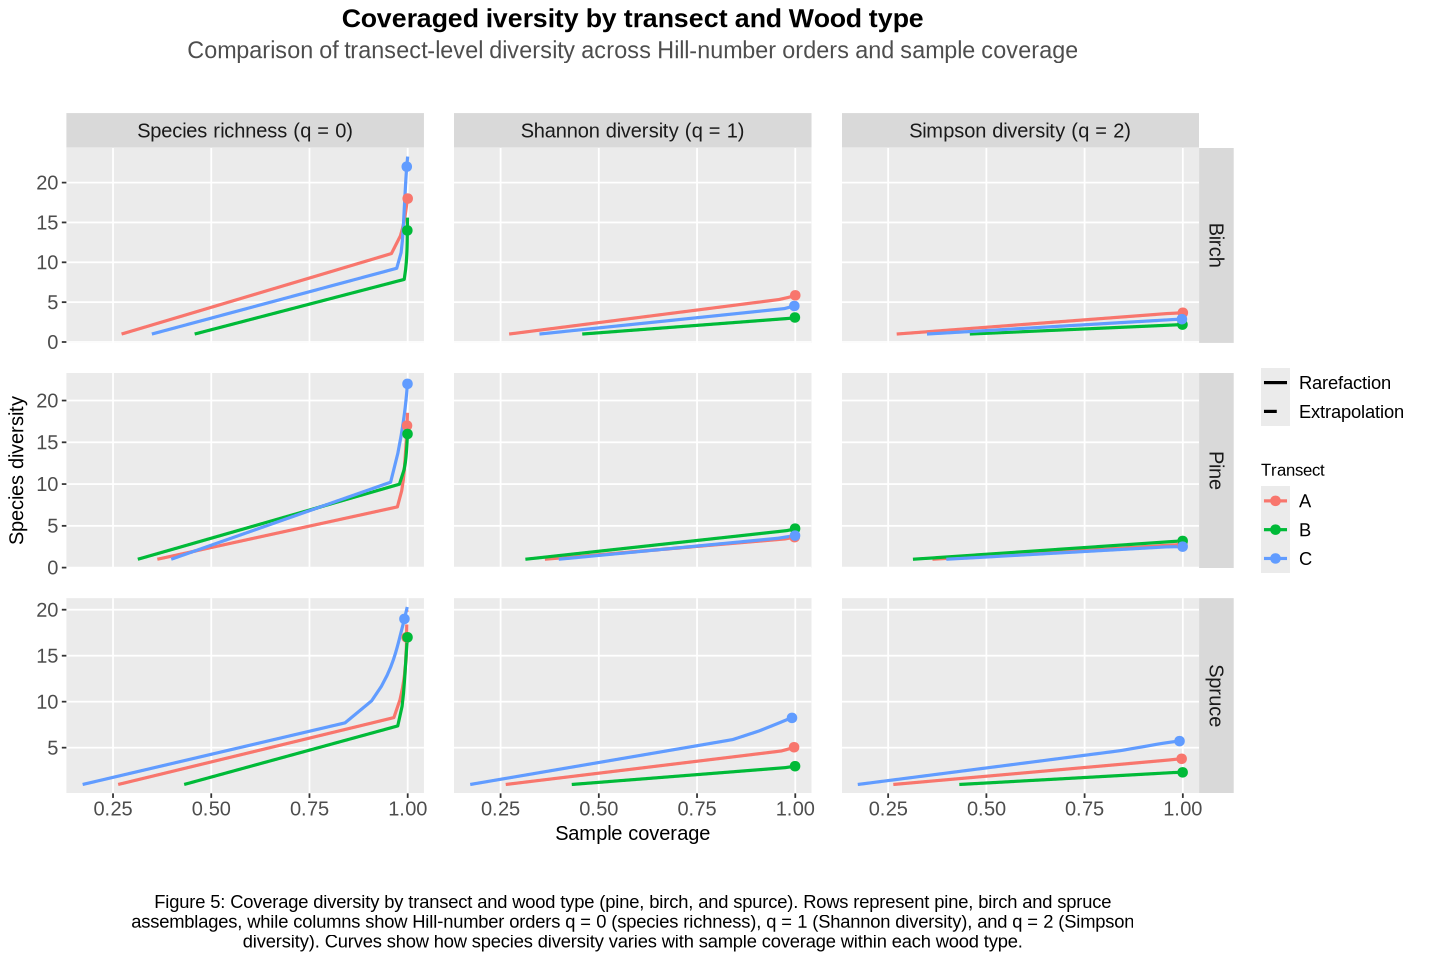

In [63]:
title_text <- paste0(
    "Coveraged iversity by transect and Wood type"
)

subtitle_text <- paste0(
    "Comparison of transect-level diversity across Hill-number orders and sample coverage"
)

caption_text <- paste0(
    "Figure 5: Coverage diversity by transect and wood type (pine, birch, and spurce). ",
    "Rows represent pine, birch and spruce assemblages, while columns show Hill-number orders ",
    "q = 0 (species richness), q = 1 (Shannon diversity), and q = 2 (Simpson diversity). ",
    "Curves show how species diversity varies with sample coverage within each wood type."
)

z.figure5b <- ggplot(plot_data, aes(x = SC, y = qD)) +
    # Coverage-based diversity curves
    geom_line(
        aes(
            color = Transect,
            linetype = Method,
            group = interaction(Transect, Method)
        ),
        linewidth = 0.9
    ) +
    # Observed/reference points
    geom_point(
        data = observed_data,
        aes(
            x = SC,
            y = qD,
            color = Transect
        ),
        inherit.aes = FALSE,
        size = 2.3
    ) +
    # Hardwood on top, Softwood on bottom
    # Hill numbers across columns
    facet_grid(
        Wood.Type ~ Order.q,
        scales = "free_y"
    ) +
    scale_linetype_manual(
        values = c(
            "Rarefaction" = "solid",
            "Extrapolation" = "dashed"
        )
    ) +
    labs(
        x = "Sample coverage",
        y = "Species diversity",
        color = "Transect",
        linetype = NULL
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

options(repr.plot.width = 12, repr.plot.height = 8)
z.figure5b

## 5. Results

## A. Session Info

In [71]:
sessionInfo()

R version 4.5.3 (2026-03-11)
Platform: x86_64-conda-linux-gnu
Running under: Ubuntu 24.04.3 LTS

Matrix products: default
BLAS/LAPACK: /opt/conda/lib/libopenblasp-r0.3.30.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

time zone: Etc/UTC
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] viridis_0.6.5     viridisLite_0.4.3 vegan_2.7-5       permute_0.9-10   
 [5] tidyr_1.3.2       tibble_3.3.1      stringr_1.6.0     scales_1.4.0     
 [9] readr_2.2.0       patchwork_1.3.2   labdsv_2.3-1      mgcv_1.9-4       
[13] nlme_3.1-170      IRdisplay_1.1     iNEXT_3.0.2       gt_1.3.0         
[17] ggplot2_4

## B. Citations

In [72]:
citation("iNEXT")

To cite iNEXT in publications use:

  T. C. Hsieh, K. H. Ma and Anne Chao. 2025 iNEXT: iNterpolation and
  EXTrapolation for species diversity. R package version 3.0.2 URL:
  http://chao.stat.nthu.edu.tw/wordpress/software-download/.

  Anne Chao, Nicholas J. Gotelli, T. C. Hsieh, Elizabeth L. Sander, K.
  H. Ma, Robert K. Colwell, and Aaron M. Ellison 2014. Rarefaction and
  extrapolation with Hill numbers: a framework for sampling and
  estimation in species diversity studies. Ecological Monographs
  84:45-67.

To see these entries in BibTeX format, use 'print(<citation>,
bibtex=TRUE)', 'toBibtex(.)', or set
'options(citation.bibtex.max=999)'.

In [73]:
citation("tidyverse")

To cite package ‘tidyverse’ in publications use:

  Wickham H, Averick M, Bryan J, Chang W, McGowan LD, François R,
  Grolemund G, Hayes A, Henry L, Hester J, Kuhn M, Pedersen TL, Miller
  E, Bache SM, Müller K, Ooms J, Robinson D, Seidel DP, Spinu V,
  Takahashi K, Vaughan D, Wilke C, Woo K, Yutani H (2019). “Welcome to
  the tidyverse.” _Journal of Open Source Software_, *4*(43), 1686.
  doi:10.21105/joss.01686 <https://doi.org/10.21105/joss.01686>.

A BibTeX entry for LaTeX users is

  @Article{,
    title = {Welcome to the {tidyverse}},
    author = {Hadley Wickham and Mara Averick and Jennifer Bryan and Winston Chang and Lucy D'Agostino McGowan and Romain François and Garrett Grolemund and Alex Hayes and Lionel Henry and Jim Hester and Max Kuhn and Thomas Lin Pedersen and Evan Miller and Stephan Milton Bache and Kirill Müller and Jeroen Ooms and David Robinson and Dana Paige Seidel and Vitalie Spinu and Kohske Takahashi and Davis Vaughan and Claus Wilke and Kara Woo and Hiroaki Yu